<a href="https://colab.research.google.com/github/vivianthanou/hobbit_folder/blob/master/Graph_clustering_approaches_for_mental_fatigue_detection_in_EEG_networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

base_path = "/content/drive/MyDrive/1. Thesis Project/Vivian Thanou Thesis/401 PLI networks"
save_path = "/content/drive/MyDrive/1. Thesis Project"

print(os.listdir(base_path))

['CG401_chanlocs.csv', 'rest', 'fatigue']


In [ ]:
import os
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.axes_grid1 import make_axes_locatable

# Check Files and Shapes

In [ ]:
import numpy as np
import pandas as pd

alpha_f = np.load(base_path + "/fatigue/PLIalphaF.npy")
alpha_f_total = np.load(base_path + "/fatigue/PLIalphaF_total.npy")

chanlocs = pd.read_csv(base_path + "/CG401_chanlocs.csv")

print("PLIalphaF shape:", alpha_f.shape)
print("PLIalphaF_total shape:", alpha_f_total.shape)
print("Channels file:")
print(chanlocs.head())

PLIalphaF shape: (20, 1953)
PLIalphaF_total shape: (20, 63, 63)
Channels file:
  labels  theta    radius          X          Y          Z  sph_theta  \
0    Fp1    -18  0.511111  80.790558  26.250444  -2.966457         18   
1    AF7    -36  0.511111  68.724554  49.931311  -2.966457         36   
2    AF3    -25  0.411111  74.051912  34.530973  23.429175         25   
3     F1    -22  0.277778  60.372443  24.392050  54.636947         22   
4     F3    -39  0.333333  57.207392  46.325633  42.500000         39   

   sph_phi  sph_radius  type      ref  urchan  
0       -2          85   NaN  average       1  
1       -2          85   NaN  average       2  
2       16          85   NaN  average       3  
3       40          85   NaN  average       4  
4       30          85   NaN  average       5  


In [ ]:
print(alpha_f[0, :10])
print(alpha_f_total[0, :10, :10 ])

[0.01792877 0.01136892 0.07608093 0.03025065 0.05440684 0.13844381
 0.03849478 0.10710724 0.07825278 0.15533098]
[[0.         0.01792877 0.01136892 0.03025065 0.03849478 0.07452962
  0.07834142 0.08410345 0.08454668 0.03849478]
 [0.01792877 0.         0.07608093 0.05440684 0.10710724 0.14801764
  0.06597522 0.03455001 0.07967112 0.09810961]
 [0.01136892 0.07608093 0.         0.13844381 0.07825278 0.02375729
  0.02036655 0.01088137 0.02787935 0.07036323]
 [0.03025065 0.05440684 0.13844381 0.         0.15533098 0.1327261
  0.01945793 0.00166212 0.01309753 0.02451078]
 [0.03849478 0.10710724 0.07825278 0.15533098 0.         0.15515369
  0.07652417 0.04966425 0.00547393 0.08614232]
 [0.07452962 0.14801764 0.02375729 0.1327261  0.15515369 0.
  0.10524566 0.06468985 0.02083195 0.19092259]
 [0.07834142 0.06597522 0.02036655 0.01945793 0.07652417 0.10524566
  0.         0.00201671 0.05990293 0.13578441]
 [0.08410345 0.03455001 0.01088137 0.00166212 0.04966425 0.06468985
  0.00201671 0.        

In [ ]:
print("dtype:", alpha_f.dtype)
print("min:", np.min(alpha_f))
print("max:", np.max(alpha_f))
print("mean:", np.mean(alpha_f))

dtype: float64
min: 0.0
max: 0.4014514303468785
mean: 0.05012158943753641


In [ ]:
A = alpha_f_total[0, :, :]

print(np.allclose(A, A.T))

True


In [ ]:
print(np.diag(A))

[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


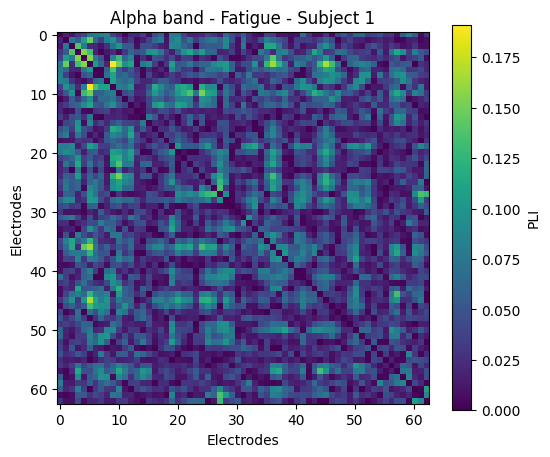

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 5))
plt.imshow(A)
plt.colorbar(label="PLI")
plt.title("Alpha band - Fatigue - Subject 1")
plt.xlabel("Electrodes")
plt.ylabel("Electrodes")
plt.show()

In [ ]:
chanlocs = pd.read_csv(base_path + "/CG401_chanlocs.csv")
print(chanlocs.head())
print(chanlocs.columns)

  labels  theta    radius          X          Y          Z  sph_theta  \
0    Fp1    -18  0.511111  80.790558  26.250444  -2.966457         18   
1    AF7    -36  0.511111  68.724554  49.931311  -2.966457         36   
2    AF3    -25  0.411111  74.051912  34.530973  23.429175         25   
3     F1    -22  0.277778  60.372443  24.392050  54.636947         22   
4     F3    -39  0.333333  57.207392  46.325633  42.500000         39   

   sph_phi  sph_radius  type      ref  urchan  
0       -2          85   NaN  average       1  
1       -2          85   NaN  average       2  
2       16          85   NaN  average       3  
3       40          85   NaN  average       4  
4       30          85   NaN  average       5  
Index(['labels', 'theta', 'radius', 'X', 'Y', 'Z', 'sph_theta', 'sph_phi',
       'sph_radius', 'type', 'ref', 'urchan'],
      dtype='object')


# Load Files #


In [ ]:
N_SUBJECTS = 20
N_CHANNELS = 63
N_EDGES = N_CHANNELS * (N_CHANNELS - 1) // 2  # 1953

files = {
    "fatigue": {
        "delta": {
            "vector": "PLIdeltaF.npy",
            "matrix": "PLIdeltaF_total.npy"
        },
        "theta": {
            "vector": "PLIthetaF.npy",
            "matrix": "PLIthetaF_total.npy"
        },
        "alpha": {
            "vector": "PLIalphaF.npy",
            "matrix": "PLIalphaF_total.npy"
        },
        "beta": {
            "vector": "PLIbetaF.npy",
            "matrix": "PLIbetaF_total.npy"
        },
        "gamma": {
            "vector": "PLIgammaF.npy",
            "matrix": "PLIgammaF_total.npy"
        }
    },

    "rest": {
        "delta": {
            "vector": "PLIdeltaR.npy",
            "matrix": "PLIdeltaR_total.npy"
        },
        "theta": {
            "vector": "PLIthetaR.npy",
            "matrix": "PLIthetaR_total.npy"
        },
        "alpha": {
            "vector": "PLIalphaR.npy",
            "matrix": "PLIalphaR_total.npy"
        },
        "beta": {
            "vector": "PLIbetaR.npy",
            "matrix": "PLIbetaR_total.npy"
        },
        "gamma": {
            "vector": "PLIgammaR.npy",
            "matrix": "PLIgammaR_total.npy"
        }
    }
}

In [ ]:
results = []

for state, bands in files.items():
    state_path = os.path.join(base_path, state)

    for band, representations in bands.items():
        for representation, filename in representations.items():

            file_path = os.path.join(state_path, filename)

            info = {
                "state": state,
                "band": band,
                "representation": representation,
                "folder": state_path,
                "filename": filename,
                "file_exists": os.path.exists(file_path),
                "shape": None,
                "expected_shape": None,
                "shape_ok": None,
                "dtype": None,
                "min": None,
                "max": None,
                "mean": None,
                "has_nan": None,
                "symmetric_all_subjects": None,
                "max_asymmetry": None,
                "zero_diagonal_all_subjects": None,
                "max_abs_diagonal": None
            }

            if not os.path.exists(file_path):
                results.append(info)
                continue

            data = np.load(file_path)

            info["shape"] = data.shape
            info["dtype"] = data.dtype
            info["min"] = np.min(data)
            info["max"] = np.max(data)
            info["mean"] = np.mean(data)
            info["has_nan"] = np.isnan(data).any()

            if representation == "vector":
                expected_shape = (N_SUBJECTS, N_EDGES)
                info["expected_shape"] = expected_shape
                info["shape_ok"] = data.shape == expected_shape

            elif representation == "matrix":
                expected_shape = (N_SUBJECTS, N_CHANNELS, N_CHANNELS)
                info["expected_shape"] = expected_shape
                info["shape_ok"] = data.shape == expected_shape

                if data.shape == expected_shape:
                    symmetric_checks = []
                    zero_diag_checks = []
                    asymmetry_values = []
                    diagonal_values = []

                    for subject_idx in range(N_SUBJECTS):
                        A = data[subject_idx, :, :]

                        symmetric_checks.append(np.allclose(A, A.T))
                        zero_diag_checks.append(np.allclose(np.diag(A), 0))

                        asymmetry_values.append(np.max(np.abs(A - A.T)))
                        diagonal_values.append(np.max(np.abs(np.diag(A))))

                    info["symmetric_all_subjects"] = all(symmetric_checks)
                    info["max_asymmetry"] = max(asymmetry_values)
                    info["zero_diagonal_all_subjects"] = all(zero_diag_checks)
                    info["max_abs_diagonal"] = max(diagonal_values)

            results.append(info)

summary_df = pd.DataFrame(results)

summary_df

,state,band,representation,folder,filename,file_exists,shape,expected_shape,shape_ok,dtype,min,max,mean,has_nan,symmetric_all_subjects,max_asymmetry,zero_diagonal_all_subjects,max_abs_diagonal
0,fatigue,delta,vector,/content/drive/MyDrive/1. Thesis Project/Vivia...,PLIdeltaF.npy,True,"(20, 1953)","(20, 1953)",True,float64,0.0,0.414022,0.042154,False,None,NaN,None,NaN
1,fatigue,delta,matrix,/content/drive/MyDrive/1. Thesis Project/Vivia...,PLIdeltaF_total.npy,True,"(20, 63, 63)","(20, 63, 63)",True,float64,0.0,0.414022,0.041485,False,True,0.0,True,0.0
2,fatigue,theta,vector,/content/drive/MyDrive/1. Thesis Project/Vivia...,PLIthetaF.npy,True,"(20, 1953)","(20, 1953)",True,float64,0.0,0.272887,0.048540,False,None,NaN,None,NaN
3,fatigue,theta,matrix,/content/drive/MyDrive/1. Thesis Project/Vivia...,PLIthetaF_total.npy,True,"(20, 63, 63)","(20, 63, 63)",True,float64,0.0,0.272887,0.047770,False,True,0.0,True,0.0
4,fatigue,alpha,vector,/content/drive/MyDrive/1. Thesis Project/Vivia...,PLIalphaF.npy,True,"(20, 1953)","(20, 1953)",True,float64,0.0,0.401451,0.050122,False,None,NaN,None,NaN
5,fatigue,alpha,matrix,/content/drive/MyDrive/1. Thesis Project/Vivia...,PLIalphaF_total.npy,True,"(20, 63, 63)","(20, 63, 63)",True,float64,0.0,0.401451,0.049326,False,True,0.0,True,0.0
6,fatigue,beta,vector,/content/drive/MyDrive/1. Thesis Project/Vivia...,PLIbetaF.npy,True,"(20, 1953)","(20, 1953)",True,float64,0.0,0.367104,0.034354,False,None,NaN,None,NaN
7,fatigue,beta,matrix,/content/drive/MyDrive/1. Thesis Project/Vivia...,PLIbetaF_total.npy,True,"(20, 63, 63)","(20, 63, 63)",True,float64,0.0,0.367104,0.033809,False,True,0.0,True,0.0
8,fatigue,gamma,vector,/content/drive/MyDrive/1. Thesis Project/Vivia...,PLIgammaF.npy,True,"(20, 1953)","(20, 1953)",True,float64,0.0,0.427608,0.030240,False,None,NaN,None,NaN
9,fatigue,gamma,matrix,/content/drive/MyDrive/1. Thesis Project/Vivia...,PLIgammaF_total.npy,True,"(20, 63, 63)","(20, 63, 63)",True,float64,0.0,0.427608,0.029760,False,True,0.0,True,0.0


In [ ]:
chanlocs_path = os.path.join(base_path, "CG401_chanlocs.csv")

chanlocs = pd.read_csv(chanlocs_path)

labels = chanlocs["labels"].tolist()

print("Number of labels:", len(labels))
print(labels)

Number of labels: 63
['Fp1', 'AF7', 'AF3', 'F1', 'F3', 'F5', 'F7', 'FT7', 'FC5', 'FC3', 'FC1', 'C1', 'C3', 'C5', 'T7', 'TP7', 'CP5', 'CP3', 'CP1', 'P1', 'P3', 'P5', 'P7', 'P9', 'PO7', 'PO3', 'O1', 'Oz', 'POz', 'Pz', 'CPz', 'Fpz', 'Fp2', 'AF8', 'AF4', 'Afz', 'Fz', 'F2', 'F4', 'F6', 'F8', 'FT8', 'FC6', 'FC4', 'FC2', 'FCz', 'Cz', 'C2', 'C4', 'C6', 'T8', 'TP8', 'CP6', 'CP4', 'CP2', 'P2', 'P4', 'P6', 'P8', 'P10', 'PO8', 'PO4', 'O2']


## PLI values comparison on the initial graphs

In [19]:
import os
import csv
import numpy as np

save_path = "/content/drive/MyDrive/1. Thesis Project/PLI_comparison"

bands = ["alpha", "beta", "gamma","delta", "theta"]
n_connections = 63 * 62 // 2   # 1953

for band in bands:

    rest_values = np.load(base_path + f"/rest/PLI{band}R.npy")
    fatigue_values = np.load(base_path + f"/fatigue/PLI{band}F.npy")

    output_file = os.path.join(save_path,f"PLI_values_comparison_{band}.csv")

    with open(output_file, "w", newline="") as file:
        writer = csv.writer(file)

        writer.writerow([f"{band} band", "Rest"] + [""] * (n_connections - 1) + ["Fatigue"] + [""] * (n_connections - 1))
        writer.writerow( ["Subject"] + list(range(1, n_connections + 1)) + list(range(1, n_connections + 1)))

        for subject in range(20):
            writer.writerow([subject + 1] + list(rest_values[subject]) + list(fatigue_values[subject]))

        writer.writerow(["p_value"] + [""] * n_connections + [""] * n_connections)

## Helper Functions

### Graph Construction

Υπάρχουν οι ακόλουθες συναρτήσεις
1) threshold_proportional_upper: κρατάμε ένα μέρος των συνδέσεων
2) build_graph_from_adjacency
3) add_distance_from_weight

In [12]:
def threshold_proportional_upper(A, proportion):
    """
    Keeps the strongest proportion of edges from the upper triangle
    and returns a symmetric thresholded adjacency matrix.
    """

    A = np.array(A, dtype=float).copy()

    # Force symmetry and remove self-connections
    A = (A + A.T) / 2
    np.fill_diagonal(A, 0)

    n = A.shape[0]

    # Get upper triangle indices, excluding diagonal
    triu_idx = np.triu_indices(n, k=1)
    weights = A[triu_idx]

    n_edges = len(weights)
    n_keep = int(np.round(proportion * n_edges))

    if n_keep < 1:
        raise ValueError("Threshold proportion too low; no edges would be kept.")

    # Find threshold value
    sorted_indices = np.argsort(weights)[::-1]
    keep_indices = sorted_indices[:n_keep]

    A_thresh = np.zeros_like(A)

    rows = triu_idx[0][keep_indices]
    cols = triu_idx[1][keep_indices]

    A_thresh[rows, cols] = A[rows, cols]
    A_thresh[cols, rows] = A[rows, cols]

    return A_thresh

def build_graph_from_adjacency(A, labels):
    """
    Builds a weighted undirected graph from a thresholded adjacency matrix.
    Only positive edges are included.
    """

    G = nx.Graph()

    for idx, label in enumerate(labels):
        G.add_node(idx, label=label)

    n = A.shape[0]

    for i in range(n):
        for j in range(i + 1, n):
            weight = float(A[i, j])

            if weight > 0:
                G.add_edge(i, j, weight=weight)

    return G

def add_distance_from_weight(G):
    """
    Converts PLI weight to distance.
    Strong PLI = short distance.
    """

    for u, v, data in G.edges(data=True):
        data["distance"] = 1.0 / data["weight"]

    return G

In [13]:
A_clean = threshold_proportional_upper(A, 0.30)
G_pos = build_graph_from_adjacency(A_clean, labels)
G_pos = add_distance_from_weight(G_pos)

metrics = {}

metrics["state"] = state
metrics["band"] = band
metrics["subject"] = subject_idx + 1
metrics["n_nodes"] = G_pos.number_of_nodes()
metrics["n_edges_all"] = G_pos.number_of_edges()
metrics["density_all"] = nx.density(G_pos)
metrics["n_edges_positive"] = G_pos.number_of_edges()
metrics["density_positive"] = nx.density(G_pos)
metrics["is_connected_positive"] = nx.is_connected(G_pos)

## Anatomical Clustering

Grouping Περιοχών

    Frontal:  Fp, AF, F
    Central:  FC, C, CP
    Temporal: FT, T
    Parietal: TP, P
    Occipital: PO, O

Τρόπος Διαχείρισης midline ηλεκτροδίων --> soft midline assignment 50% δεξιά συνεισφορά και 50% αριστερά συνεισφορά

Χρήση 2 συναρτήσεων:
1) get_anatomical_region_B: ορίζεται σε ποια περιοχή ανήκει το κάθε ηλεκτρόδιο
2) get_electrode_side: ορίζεται σε ποιο ημισφαίριο βρίσκεται το κάθε ηλεκτρόδιο


In [ ]:
import re
import numpy as np
import pandas as pd
import seaborn as sns

# Final 10 regions: 5 anatomical regions × 2 hemispheres
region_names = [
    "left_frontal", "right_frontal",
    "left_central", "right_central",
    "left_temporal", "right_temporal",
    "left_parietal", "right_parietal",
    "left_occipital", "right_occipital"
]

region_to_idx = {region: i for i, region in enumerate(region_names)}

def get_anatomical_region_B(label):
    """
    Anatomical grouping B:

    Frontal:  Fp, AF, F
    Central:  FC, C, CP
    Temporal: FT, T
    Parietal: TP, P
    Occipital: PO, O
    """

    label = label.upper()

    # Order matters: check two-letter prefixes before one-letter prefixes
    if label.startswith("FP") or label.startswith("AF"):
        return "frontal"

    if label.startswith("FC") or label.startswith("CP"):
        return "central"

    if label.startswith("FT"):
        return "temporal"

    if label.startswith("TP"):
        return "parietal"

    if label.startswith("PO"):
        return "occipital"

    if label.startswith("F"):
        return "frontal"

    if label.startswith("C"):
        return "central"

    if label.startswith("T"):
        return "temporal"

    if label.startswith("P"):
        return "parietal"

    if label.startswith("O"):
        return "occipital"

    raise ValueError(f"Unknown electrode label: {label}")


def get_electrode_side(label):
    """
    EEG convention:
    odd number  -> left hemisphere
    even number -> right hemisphere
    z           -> midline
    """

    label = label.upper()

    if label.endswith("Z"):
        return "midline"

    match = re.search(r"(\d+)$", label)

    if match is None:
        return "midline"

    number = int(match.group(1))

    if number % 2 == 1:
        return "left"
    else:
        return "right"

# Membership matrix:
# shape = 63 electrodes × 10 regions
# Normal electrodes have membership 1 in one region.
# Midline z electrodes have membership 0.5 left + 0.5 right.
membership = np.zeros((len(labels), len(region_names)))

electrode_rows = []

for electrode_idx, label in enumerate(labels):

    anatomical_region = get_anatomical_region_B(label)
    side = get_electrode_side(label)

    if side in ["left", "right"]:
        final_region = f"{side}_{anatomical_region}"
        membership[electrode_idx, region_to_idx[final_region]] = 1.0

        assignment_text = final_region

    elif side == "midline":
        left_region = f"left_{anatomical_region}"
        right_region = f"right_{anatomical_region}"

        membership[electrode_idx, region_to_idx[left_region]] = 0.5
        membership[electrode_idx, region_to_idx[right_region]] = 0.5

        assignment_text = f"0.5 {left_region} + 0.5 {right_region}"

    electrode_rows.append({
        "index": electrode_idx,
        "electrode": label,
        "anatomical_region": anatomical_region,
        "side": side,
        "assignment": assignment_text
    })


electrode_grouping_df = pd.DataFrame(electrode_rows)

print("Electrode grouping:")
display(electrode_grouping_df)

print("\nEffective group sizes:")
effective_group_sizes = pd.Series(membership.sum(axis=0), index=region_names)
display(effective_group_sizes)

# Safety check: every electrode should contribute exactly 1 in total
assert np.allclose(membership.sum(axis=1), 1.0), "Some electrodes do not sum to total membership 1."

Electrode grouping:


,index,electrode,anatomical_region,side,assignment
0,0,Fp1,frontal,left,left_frontal
1,1,AF7,frontal,left,left_frontal
2,2,AF3,frontal,left,left_frontal
3,3,F1,frontal,left,left_frontal
4,4,F3,frontal,left,left_frontal
...,...,...,...,...,...
58,58,P8,parietal,right,right_parietal
59,59,P10,parietal,right,right_parietal
60,60,PO8,occipital,right,right_occipital
61,61,PO4,occipital,right,right_occipital



Effective group sizes:


,0
left_frontal,8.5
right_frontal,8.5
left_central,10.5
right_central,10.5
left_temporal,2.0
right_temporal,2.0
left_parietal,6.5
right_parietal,6.5
left_occipital,4.0
right_occipital,4.0


In [ ]:
def to_numpy_matrix(X):
    """
    Converts sparse / matrix / array input to a regular numpy array.
    """

    if hasattr(X, "toarray"):
        return X.toarray()

    return np.asarray(X, dtype=float)

def compute_regional_matrix_soft(
    PLI_matrix,
    membership,
    include_zeros=True,
    exclude_self_connections=True
):
    """
    Computes regional connectivity matrix using soft anatomical membership.

    PLI_matrix:
        63×63 thresholded PLI matrix

    membership:
        63×10 matrix.
        Each electrode contributes to one or more regions.
        For z electrodes: 0.5 left + 0.5 right.

    include_zeros=True

    exclude_self_connections=True:
        Removes electrode-to-itself connections from within-region averages.
    """

    A = to_numpy_matrix(PLI_matrix).copy()

    # Force symmetry and zero diagonal
    A = (A + A.T) / 2
    np.fill_diagonal(A, 0)

    n = A.shape[0]

    valid_connections = np.ones((n, n))

    if exclude_self_connections:
        np.fill_diagonal(valid_connections, 0)

    if not include_zeros:
        valid_connections = valid_connections * (A > 0)

    numerator = membership.T @ (A * valid_connections) @ membership
    denominator = membership.T @ valid_connections @ membership

    regional_matrix = np.divide(
        numerator,
        denominator,
        out=np.zeros_like(numerator),
        where=denominator != 0
    )

    return regional_matrix


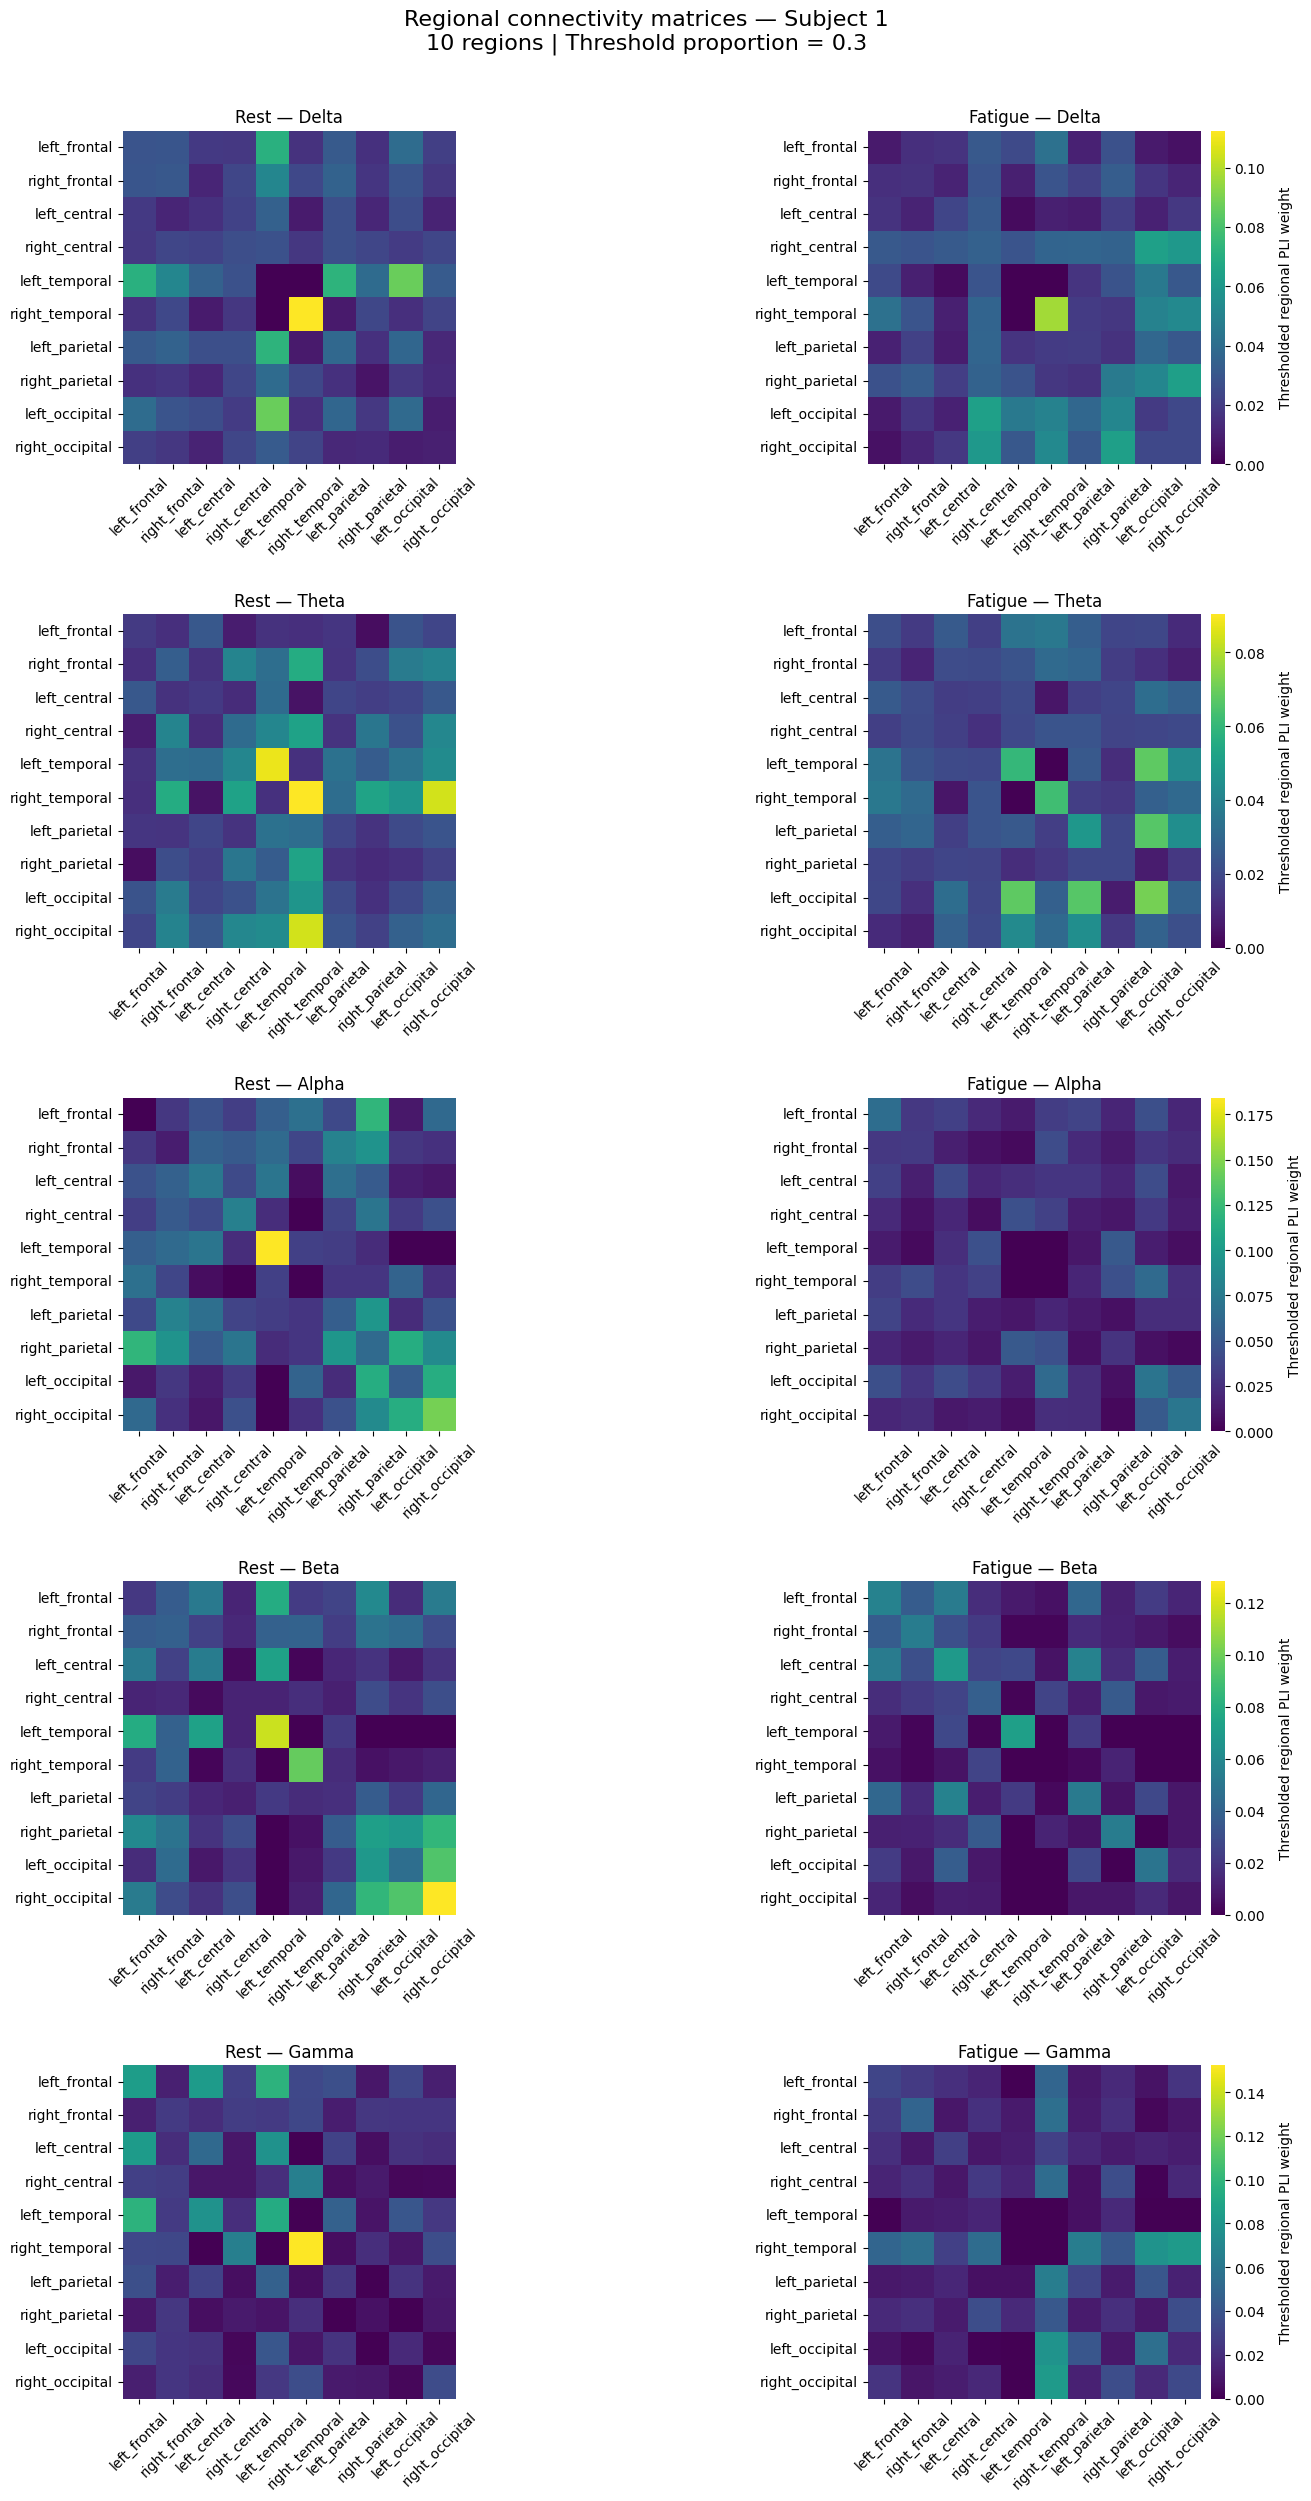

In [ ]:
subject_idx = 0              # 0 = Subject 1
threshold_proportion = 0.30

state_order = ["rest", "fatigue"]
band_order = ["delta", "theta", "alpha", "beta", "gamma"]

state_titles = {
    "rest": "Rest",
    "fatigue": "Fatigue"
}

# 1. Threshold 63x63 graph first, then create 10x10 regional matrix for each state and band
regional_matrices = {}

for band in band_order:
    for state in state_order:

        matrix_filename = files[state][band]["matrix"]
        matrix_path = os.path.join(base_path, state, matrix_filename)

        pli_matrix_all = np.load(matrix_path)

        # 63x63 PLI matrix for one subject
        A = pli_matrix_all[subject_idx, :, :]

        # Thresholding at electrode level
        G = threshold_proportional_upper(A, threshold_proportion)
        PLI_matrix = G

        # Create 10x10 regional matrix
        num_regions = len(region_names)
        regional_matrix = np.zeros((num_regions, num_regions))

        regional_matrix = compute_regional_matrix_soft(PLI_matrix=PLI_matrix, membership=membership, include_zeros=True, exclude_self_connections=True)

        regional_matrices[(state, band)] = regional_matrix


# 2. One common scale per band: Rest and Fatigue share the same vmax

band_vmax = {
    band: max(
        regional_matrices[("rest", band)].max(),
        regional_matrices[("fatigue", band)].max()
    )
    for band in band_order
}

# 3. Plot: Rest and Fatigue side-by-side for each band
fig, axes = plt.subplots(
    nrows=len(band_order),
    ncols=len(state_order),
    figsize=(17, 27)
)

for row_idx, band in enumerate(band_order):

    for col_idx, state in enumerate(state_order):

        ax = axes[row_idx, col_idx]
        A_10_thresh = regional_matrices[(state, band)]

        # Colorbar only beside the Fatigue plot of each band row
        show_cbar = (state == "fatigue")

        if show_cbar:
            divider = make_axes_locatable(ax)
            cax = divider.append_axes("right", size="4%", pad=0.10)
        else:
            cax = None

        sns.heatmap(
            A_10_thresh,
            ax=ax,
            cmap="viridis",
            vmin=0,
            vmax=band_vmax[band],
            square=True,
            cbar=show_cbar,
            cbar_ax=cax,
            xticklabels=region_names,
            yticklabels=region_names
        )

        ax.set_title(
            f"{state_titles[state]} — {band.capitalize()}",
            fontsize=12
        )

        ax.tick_params(axis="x", rotation=45)
        ax.tick_params(axis="y", rotation=0)

        if show_cbar:
            cax.set_ylabel(
                "Thresholded regional PLI weight",
                rotation=90,
                labelpad=10
            )

fig.suptitle(
    f"Regional connectivity matrices — Subject {subject_idx + 1}\n"
    f"10 regions | Threshold proportion = {threshold_proportion}",
    fontsize=16,
    y=0.995
)

fig.subplots_adjust(
    top=0.95,
    hspace=0.45,
    wspace=0.35
)

plt.show()

## Metrics

### Helper functions

1. weighted_global_efficiency(G) --> πόσο αποτελεσματικά επικοινωνεί συνολικά το δίκτυο. Ισχυρές συνδέσεις PLI αντιστοιχούν σε μικρές αποστάσεις, άρα αυξάνουν την efficiency.

2. weighted_local_efficiency_per_node(G) --> τοπική efficiency για κάθε κόμβο χωριστά: πόσο καλά επικοινωνούν μεταξύ τους οι γείτονές του όταν αφαιρεθεί ο ίδιος.

3. nodal_path_length(G) --> μέση weighted shortest-path distance προς όλους τους άλλους κόμβους.

4. small_worldness_sigma(G) -->

5. louvain_modularity(G) --> Βρίσκει αυτόματα communities με Louvain και επιστρέφει πόσο καθαρά διαχωρίζεται ο γράφος σε κοινότητες (louvain_modularity) kai πόσες κοινότητες βρέθηκαν (louvain_n_communities)

In [1]:
def weighted_global_efficiency(G, distance="distance"):
    """
    Weighted global efficiency.
    Disconnected node pairs contribute 0.
    """

    n = G.number_of_nodes()

    if n <= 1:
        return np.nan

    lengths = dict(nx.all_pairs_dijkstra_path_length(G, weight=distance))

    total_efficiency = 0

    for u in G.nodes():
        for v, d in lengths[u].items():
            if u != v and d > 0:
                total_efficiency += 1 / d

    return total_efficiency / (n * (n - 1))


def weighted_local_efficiency(G, distance="distance"):
    """
    Weighted local efficiency averaged across nodes.
    """

    local_efficiencies = []

    for node in G.nodes():
        neighbors = list(G.neighbors(node))

        if len(neighbors) < 2:
            local_efficiencies.append(0)
        else:
            subgraph = G.subgraph(neighbors).copy()
            local_efficiencies.append(
                weighted_global_efficiency(subgraph, distance=distance)
            )

    return np.mean(local_efficiencies)

def weighted_local_efficiency_per_node(G, distance="distance"):
    """
    Weighted local efficiency for each node separately.
    """

    local_efficiency = {}

    for node in G.nodes():

        neighbors = list(G.neighbors(node))

        if len(neighbors) < 2:
            local_efficiency[node] = 0.0

        else:
            neighborhood_graph = G.subgraph(neighbors).copy()

            local_efficiency[node] = weighted_global_efficiency(
                neighborhood_graph,
                distance=distance
            )

    return local_efficiency

def nodal_path_length(G, distance="distance"):
    """
    Mean weighted shortest-path length from each node
    to all other nodes.

    Returns NaN for a node when the graph is disconnected.
    """

    path_lengths = {}

    for node in G.nodes():

        lengths = nx.single_source_dijkstra_path_length(
            G,
            source=node,
            weight=distance
        )

        if len(lengths) < G.number_of_nodes():
            path_lengths[node] = np.nan

        else:
            path_lengths[node] = np.mean([
                path_distance
                for other_node, path_distance in lengths.items()
                if other_node != node
            ])

    return path_lengths

#old version
def small_worldness_sigma(G, n_random=20, seed=42):
    """
    Small-worldness:
    sigma = (C / C_random) / (L / L_random)

    Here it is calculated on an unweighted version of G_pos.
    """

    G_unweighted = nx.Graph()
    G_unweighted.add_nodes_from(G.nodes())
    G_unweighted.add_edges_from(G.edges())

    if G_unweighted.number_of_edges() == 0:
        return np.nan, np.nan, np.nan, np.nan, np.nan

    if not nx.is_connected(G_unweighted):
        largest_cc = max(nx.connected_components(G_unweighted), key=len)
        G_unweighted = G_unweighted.subgraph(largest_cc).copy()

    n = G_unweighted.number_of_nodes()
    m = G_unweighted.number_of_edges()

    if n < 3 or m < n - 1:
        return np.nan, np.nan, np.nan, np.nan, np.nan

    C = nx.average_clustering(G_unweighted)
    L = nx.average_shortest_path_length(G_unweighted)

    rng = np.random.default_rng(seed)

    C_random_values = []
    L_random_values = []

    for _ in range(n_random):
        for attempt in range(100):
            random_seed = int(rng.integers(0, 1_000_000))
            G_random = nx.gnm_random_graph(n, m, seed=random_seed)

            if nx.is_connected(G_random):
                C_random_values.append(nx.average_clustering(G_random))
                L_random_values.append(nx.average_shortest_path_length(G_random))
                break

    if len(C_random_values) == 0:
        return C, L, np.nan, np.nan, np.nan

    C_random = np.mean(C_random_values)
    L_random = np.mean(L_random_values)

    if C_random == 0 or L_random == 0:
        sigma = np.nan
    else:
        sigma = (C / C_random) / (L / L_random)

    return C, L, C_random, L_random, sigma

# We use this one
def small_worldness_sigma_unweighted(G, n_random=100, niter=10, seed=42):
    """
    Binary small-worldness using degree-preserving random reference graphs.

    Returns NaN if the observed graph is disconnected.
    """
    G_binary = nx.Graph()
    G_binary.add_nodes_from(G.nodes())
    G_binary.add_edges_from((u, v) for u, v in G.edges())

    if G_binary.number_of_nodes() < 3:
        return np.nan, np.nan, np.nan, np.nan, np.nan

    # Do not switch to the largest component for only some subjects.
    if not nx.is_connected(G_binary):
        return np.nan, np.nan, np.nan, np.nan, np.nan

    C = nx.average_clustering(G_binary)
    L = nx.average_shortest_path_length(G_binary)

    rng = np.random.default_rng(seed)
    C_random_values = []
    L_random_values = []

    for _ in range(n_random):
        random_seed = int(rng.integers(0, 2**32 - 1))

        G_random = nx.random_reference(
            G_binary,
            niter=niter,
            connectivity=True,
            seed=random_seed
        )

        C_random_values.append(nx.average_clustering(G_random))
        L_random_values.append(nx.average_shortest_path_length(G_random))

    C_random = np.mean(C_random_values)
    L_random = np.mean(L_random_values)

    sigma = (
        (C / C_random) / (L / L_random)
        if C_random > 0 and L_random > 0
        else np.nan
    )

    return C, L, C_random, L_random, sigma

def louvain_modularity(G, weight="weight", n_restarts=50, seed=42):
    if G.number_of_edges() == 0:
        return np.nan, np.nan

    rng = np.random.default_rng(seed)

    best_Q = -np.inf
    best_n_communities = np.nan

    for _ in range(n_restarts):
        run_seed = int(rng.integers(0, 2**32 - 1))

        communities = nx.community.louvain_communities(G, weight=weight, seed=run_seed)

        Q = nx.community.modularity(G, communities, weight=weight)

        if Q > best_Q:
            best_Q = Q
            best_n_communities = len(communities)

    return best_Q, best_n_communities

def calculate_graph_metrics(G, weight="weight", distance="distance", n_random=20, seed=42):
    """
    Calculates graph metrics for one graph.

    Returns:
        nodal_metrics: dictionary with one set of values per node
        global_metrics: dictionary with one set of values per graph
    """

    if G.number_of_nodes() == 0:
        raise ValueError("The graph has no nodes.")

    # Nodal metrics
    strengths = dict(G.degree(weight=weight))

    clustering = nx.clustering(G, weight=weight)
    triangles = nx.triangles(G)
    degrees = dict(G.degree())

    weighted_triangle_proxy = {node: clustering[node] * (degrees[node] * (degrees[node] - 1) / 2)
        for node in G.nodes()}

    local_efficiency = weighted_local_efficiency_per_node( G, distance=distance)
    path_lengths = nodal_path_length(G, distance=distance)
    nodal_metrics = {}

    for node in G.nodes():

        nodal_metrics[node] = {
            "degree": degrees[node],
            "strength": strengths[node],
            "weighted_clustering": clustering[node],
            "triangles_unweighted": triangles[node],
            "weighted_triangle_proxy": weighted_triangle_proxy[node],
            "local_efficiency": local_efficiency[node],
            "nodal_path_length": path_lengths[node]
        }

    # Global metrics
    is_connected = nx.is_connected(G)

    if is_connected:
        characteristic_path_length = nx.average_shortest_path_length(G, weight=distance)
    else:
        characteristic_path_length = np.nan

    global_efficiency = weighted_global_efficiency(G, distance=distance)
    average_local_efficiency = np.mean(list(local_efficiency.values()))
    average_weighted_clustering = nx.average_clustering(G, weight=weight)
    transitivity = nx.transitivity(G)

    C, L, C_random, L_random, sigma = small_worldness_sigma_unweighted(G, n_random=n_random, seed=seed)

    modularity, n_communities = louvain_modularity( G, weight=weight, seed=seed)

    global_metrics = {
        "n_nodes": G.number_of_nodes(),
        "n_edges": G.number_of_edges(),
        "density": nx.density(G),
        "mean_degree": np.mean(list(degrees.values())),
        "is_connected": is_connected,
        "mean_strength": np.mean(list(strengths.values())),
        "global_efficiency": global_efficiency,
        "average_local_efficiency": average_local_efficiency,
        "characteristic_path_length": characteristic_path_length,
        "average_weighted_clustering": average_weighted_clustering,
        "transitivity_unweighted": transitivity,
        "global_triangles_unweighted": sum(triangles.values()) / 3,
        "smallworld_C": C,
        "smallworld_L": L,
        "smallworld_C_random": C_random,
        "smallworld_L_random": L_random,
        "smallworld_sigma_binary": sigma,
        "louvain_modularity": modularity,
        "louvain_n_communities": n_communities
    }

    return nodal_metrics, global_metrics

## Metrics for the initial graphs

In [15]:
threshold_proportion = 0.30
results_path = os.path.join(save_path, "graph_metrics_results")
os.makedirs(results_path, exist_ok=True)

all_global_rows = []
all_nodal_rows = []

for state, bands in files.items():
    state_path = os.path.join(base_path, state)

    for band, representations in bands.items():
        file_path = os.path.join(state_path, representations["matrix"])
        data = np.load(file_path)

        print(f"Processing: {state} | {band}")

        for subject_idx in range(N_SUBJECTS):
            A = data[subject_idx, :, :]
            A_thresholded = threshold_proportional_upper(A, threshold_proportion)
            G = build_graph_from_adjacency(A_thresholded, labels)
            G = add_distance_from_weight(G)

            nodal_metrics, global_metrics = calculate_graph_metrics(G)

            all_global_rows.append({
                "subject": subject_idx + 1,
                "state": state,
                "band": band,
                "threshold_proportion": threshold_proportion,
                **global_metrics
            })

            for node, metric_values in nodal_metrics.items():
                all_nodal_rows.append({
                    "subject": subject_idx + 1,
                    "state": state,
                    "band": band,
                    "threshold_proportion": threshold_proportion,
                    "electrode_index": node,
                    "electrode": labels[node],
                    **metric_values
                })

metrics_63_global_df = pd.DataFrame(all_global_rows)
metrics_63_nodal_df = pd.DataFrame(all_nodal_rows)

metrics_63_global_df = metrics_63_global_df.sort_values(
    ["subject", "state", "band"]
).reset_index(drop=True)

metrics_63_nodal_df = metrics_63_nodal_df.sort_values(
    ["subject", "state", "band", "electrode_index"]
).reset_index(drop=True)

global_file = os.path.join(results_path, "metrics_63_global_thr_0.30.csv")
nodal_file = os.path.join(results_path, "metrics_63_nodal_thr_0.30.csv")

metrics_63_global_df.to_csv(global_file, index=False)
metrics_63_nodal_df.to_csv(nodal_file, index=False)

print(metrics_63_global_df.shape)
print(metrics_63_nodal_df.shape)

display(metrics_63_global_df.head())
display(metrics_63_nodal_df.head())

Processing: fatigue | delta
Processing: fatigue | theta
Processing: fatigue | alpha
Processing: fatigue | beta
Processing: fatigue | gamma
Processing: rest | delta
Processing: rest | theta
Processing: rest | alpha
Processing: rest | beta
Processing: rest | gamma
(200, 23)
(12600, 13)


,subject,state,band,threshold_proportion,n_nodes,n_edges,density,mean_degree,is_connected,mean_strength,...,average_weighted_clustering,transitivity_unweighted,global_triangles_unweighted,smallworld_C,smallworld_L,smallworld_C_random,smallworld_L_random,smallworld_sigma,louvain_modularity,louvain_n_communities
0,1,fatigue,alpha,0.3,63,585,0.299539,18.571429,False,1.461871,...,0.169250,0.412277,1800.0,0.423848,1.747753,0.311868,1.692068,1.315761,0.155469,5
1,1,fatigue,beta,0.3,63,585,0.299539,18.571429,False,1.530055,...,0.116829,0.427707,1837.0,0.447806,1.790058,0.311868,1.692068,1.357283,0.224237,4
2,1,fatigue,delta,0.3,63,585,0.299539,18.571429,True,1.558050,...,0.167585,0.391472,1729.0,0.413131,1.756272,0.299182,1.702995,1.338978,0.152000,4
3,1,fatigue,gamma,0.3,63,585,0.299539,18.571429,True,1.187378,...,0.086991,0.447387,1943.0,0.503429,1.760369,0.299182,1.702995,1.627842,0.218596,4
4,1,fatigue,theta,0.3,63,585,0.299539,18.571429,True,1.309140,...,0.210423,0.433393,1939.0,0.425222,1.798259,0.299182,1.702995,1.345986,0.159743,3


,subject,state,band,threshold_proportion,electrode_index,electrode,degree,strength,weighted_clustering,triangles_unweighted,weighted_triangle_proxy,local_efficiency,nodal_path_length
0,1,fatigue,alpha,0.3,0,Fp1,14,0.993285,0.158095,37,14.386602,0.053672,NaN
1,1,fatigue,alpha,0.3,1,AF7,23,1.773752,0.235707,142,59.633867,0.076356,NaN
2,1,fatigue,alpha,0.3,2,AF3,20,1.627241,0.241606,110,45.905104,0.067637,NaN
3,1,fatigue,alpha,0.3,3,F1,28,2.449505,0.117643,104,44.469216,0.047622,NaN
4,1,fatigue,alpha,0.3,4,F3,20,1.776123,0.244538,102,46.462162,0.071531,NaN


In [ ]:
import os
import numpy as np
import pandas as pd

subject_idx = 0              # 0 = Subject 1
threshold_proportion = 0.30

one_subject_global_rows = []
one_subject_nodal_rows = []

for state in state_order:
    for band in band_order:

        matrix_filename = files[state][band]["matrix"]
        matrix_path = os.path.join(base_path, state, matrix_filename)

        pli_matrix_all = np.load(matrix_path)

        # 63×63 PLI matrix
        A = np.asarray(pli_matrix_all[subject_idx], dtype=float)

        if A.shape != (len(labels), len(labels)):
            raise ValueError(
                f"Unexpected matrix shape for {state}-{band}: {A.shape}"
            )

        A_thresholded = threshold_proportional_upper(A, threshold_proportion)
        G = build_graph_from_adjacency(A_thresholded, labels)
        G = add_distance_from_weight(G)
        nodal_metrics, global_metrics = calculate_graph_metrics(G)

        # Save one line per graph
        one_subject_global_rows.append({
            "subject": subject_idx + 1,
            "state": state,
            "band": band,
            "threshold_proportion": threshold_proportion,
            **global_metrics
        })

        # Save one line per electrode
        for node, metric_values in nodal_metrics.items():

            one_subject_nodal_rows.append({
                "subject": subject_idx + 1,
                "state": state,
                "band": band,
                "threshold_proportion": threshold_proportion,
                "electrode_index": node,
                "electrode": labels[node],
                **metric_values
            })

one_subject_global_df = pd.DataFrame(one_subject_global_rows)
one_subject_nodal_df = pd.DataFrame(one_subject_nodal_rows)

display(one_subject_global_df)
display(one_subject_nodal_df.head(10))

print("Global rows:", one_subject_global_df.shape[0])
print("Nodal rows:", one_subject_nodal_df.shape[0])

,subject,state,band,threshold_proportion,n_nodes,n_edges,density,mean_degree,is_connected,mean_strength,...,average_weighted_clustering,transitivity_unweighted,global_triangles_unweighted,smallworld_C,smallworld_L,smallworld_C_random,smallworld_L_random,smallworld_sigma,louvain_modularity,louvain_n_communities
0,1,rest,delta,0.3,63,585,0.299539,18.571429,True,1.442241,...,0.202681,0.339900,1432.0,0.348423,1.755760,0.299182,1.702995,1.129587,0.165482,3
1,1,rest,theta,0.3,63,585,0.299539,18.571429,False,1.353077,...,0.181451,0.415149,1710.0,0.421590,1.724484,0.311868,1.692068,1.326411,0.221090,4
2,1,rest,alpha,0.3,63,585,0.299539,18.571429,True,3.138285,...,0.252526,0.368193,1555.0,0.415145,1.733743,0.299182,1.702995,1.362989,0.205563,3
3,1,rest,beta,0.3,63,585,0.299539,18.571429,True,1.801467,...,0.155169,0.398892,1632.0,0.439719,1.758321,0.299182,1.702995,1.423493,0.267455,3
4,1,rest,gamma,0.3,63,585,0.299539,18.571429,True,1.482491,...,0.150257,0.444543,1841.0,0.483589,1.717358,0.299182,1.702995,1.602852,0.266063,3
5,1,fatigue,delta,0.3,63,585,0.299539,18.571429,True,1.558050,...,0.167585,0.391472,1729.0,0.413131,1.756272,0.299182,1.702995,1.338978,0.152000,4
6,1,fatigue,theta,0.3,63,585,0.299539,18.571429,True,1.309140,...,0.210423,0.433393,1939.0,0.425222,1.798259,0.299182,1.702995,1.345986,0.159743,3
7,1,fatigue,alpha,0.3,63,585,0.299539,18.571429,False,1.461871,...,0.169250,0.412277,1800.0,0.423848,1.747753,0.311868,1.692068,1.315761,0.155469,5
8,1,fatigue,beta,0.3,63,585,0.299539,18.571429,False,1.530055,...,0.116829,0.427707,1837.0,0.447806,1.790058,0.311868,1.692068,1.357283,0.224237,4
9,1,fatigue,gamma,0.3,63,585,0.299539,18.571429,True,1.187378,...,0.086991,0.447387,1943.0,0.503429,1.760369,0.299182,1.702995,1.627842,0.218596,4


,subject,state,band,threshold_proportion,electrode_index,electrode,degree,strength,weighted_clustering,triangles_unweighted,weighted_triangle_proxy,local_efficiency,nodal_path_length
0,1,rest,delta,0.3,0,Fp1,30,2.527968,0.151664,109,65.973845,0.048446,17.744316
1,1,rest,delta,0.3,1,AF7,26,2.219543,0.176450,91,57.346173,0.047445,17.585690
2,1,rest,delta,0.3,2,AF3,23,1.930689,0.254045,101,64.273422,0.059287,18.997216
3,1,rest,delta,0.3,3,F1,20,1.522002,0.202209,69,38.419710,0.052237,20.073115
4,1,rest,delta,0.3,4,F3,13,1.119694,0.278864,34,21.751426,0.054948,20.226158
5,1,rest,delta,0.3,5,F5,12,0.930826,0.255103,28,16.836784,0.058322,21.724750
6,1,rest,delta,0.3,6,F7,9,0.802551,0.334543,19,12.043558,0.065701,20.159679
7,1,rest,delta,0.3,7,FT7,32,2.598449,0.184936,154,91.728090,0.051047,17.520130
8,1,rest,delta,0.3,8,FC5,33,2.547263,0.209819,192,110.784298,0.055787,17.961525
9,1,rest,delta,0.3,9,FC3,8,0.639334,0.128154,6,3.588321,0.024651,22.794224


Global rows: 10
Nodal rows: 630


## Metrics for the topological regions

In [ ]:
threshold_value = 0.30
results_path = os.path.join(save_path, "graph_metrics_results")

nodal_file = os.path.join(results_path, f"metrics_63_nodal_thr_{threshold_value:.2f}.csv")
metrics_63_nodal_df = pd.read_csv(nodal_file)

print("Loaded:", nodal_file)
print(metrics_63_nodal_df.shape)

Loaded: /content/drive/MyDrive/1. Thesis Project/graph_metrics_results/metrics_63_nodal_thr_0.30.csv
(12600, 13)


In [ ]:
# Uses nodal metrics from 63-node graph to calculate weighted average per region

metrics_63_regional_nodal_summaries = [
    "degree",
    "strength",
    "weighted_clustering",
    "triangles_unweighted",
    "weighted_triangle_proxy",
    "local_efficiency",
    "nodal_path_length"
]

membership_long_df = (pd.DataFrame(membership, columns=region_names).rename_axis("electrode_index").reset_index()
    .melt(
        id_vars="electrode_index",
        var_name="region",
        value_name="membership_weight"
    )
)

membership_long_df = membership_long_df[membership_long_df["membership_weight"] > 0]

nodal_long_df = metrics_63_nodal_df.melt(
    id_vars=[
        "subject",
        "state",
        "band",
        "threshold_proportion",
        "electrode_index"
    ],
    value_vars=metrics_63_regional_nodal_summaries,
    var_name="metric",
    value_name="value"
)

regional_long_df = nodal_long_df.merge(
    membership_long_df,
    on="electrode_index",
    how="inner"
)

regional_long_df["valid_membership_weight"] = np.where(
    regional_long_df["value"].notna(),
    regional_long_df["membership_weight"],
    0.0
)

regional_long_df["weighted_value"] = (
    regional_long_df["value"].fillna(0.0) *
    regional_long_df["valid_membership_weight"]
)

regional_summary_long_df = (
    regional_long_df
    .groupby(
        ["subject", "state", "band", "threshold_proportion", "region", "metric"],
        as_index=False
    )
    .agg(
        weighted_sum=("weighted_value", "sum"),
        valid_membership_sum=("valid_membership_weight", "sum")
    )
)

regional_summary_long_df["value"] = np.where(
    regional_summary_long_df["valid_membership_sum"] > 0,
    regional_summary_long_df["weighted_sum"] /
    regional_summary_long_df["valid_membership_sum"],
    np.nan
)
regional_metrics_df = (
    regional_summary_long_df
    .pivot(
        index=["subject", "state", "band", "threshold_proportion", "region"],
        columns="metric",
        values="value"
    )
    .reset_index()
)

regional_metrics_df.columns.name = None

regional_metrics_df["region"] = pd.Categorical(
    regional_metrics_df["region"],
    categories=region_names,
    ordered=True
)

regional_metrics_df = regional_metrics_df.sort_values(
    ["subject", "state", "band", "region"]
).reset_index(drop=True)

threshold_value = metrics_63_nodal_df["threshold_proportion"].iloc[0]

regional_file = os.path.join(
    results_path,
    f"metrics_63_regional_summaries_thr_{threshold_value:.2f}.csv"
)

regional_metrics_df.to_csv(regional_file, index=False)

print(regional_metrics_df.shape)
display(regional_metrics_df.head(10))

(2000, 12)


,subject,state,band,threshold_proportion,region,degree,local_efficiency,nodal_path_length,strength,triangles_unweighted,weighted_clustering,weighted_triangle_proxy
0,1,fatigue,alpha,0.3,left_frontal,24.411765,0.061561,NaN,2.047689,133.647059,0.189474,58.571387
1,1,fatigue,alpha,0.3,right_frontal,16.882353,0.060858,NaN,1.264152,66.352941,0.176114,27.149426
2,1,fatigue,alpha,0.3,left_central,20.761905,0.052568,NaN,1.655040,103.904762,0.155838,43.518094
3,1,fatigue,alpha,0.3,right_central,13.809524,0.055107,NaN,1.015149,56.857143,0.163542,23.021160
4,1,fatigue,alpha,0.3,left_temporal,18.500000,0.041291,NaN,1.364836,55.500000,0.107345,22.184173
5,1,fatigue,alpha,0.3,right_temporal,26.500000,0.062612,NaN,2.066485,136.500000,0.168679,56.773749
6,1,fatigue,alpha,0.3,left_parietal,16.615385,0.067711,NaN,1.317861,69.230769,0.192154,29.106149
7,1,fatigue,alpha,0.3,right_parietal,13.538462,0.050615,NaN,1.026749,48.000000,0.152083,19.213955
8,1,fatigue,alpha,0.3,left_occipital,26.250000,0.065942,NaN,2.154749,156.875000,0.198391,66.851518
9,1,fatigue,alpha,0.3,right_occipital,16.250000,0.055333,NaN,1.297154,59.625000,0.154654,25.184822


In [ ]:
threshold_proportion = 0.30
threshold_tag = f"thr_{threshold_proportion:.2f}"

results_path = os.path.join(save_path, "graph_metrics_results")
matrices_10_path = os.path.join(
    results_path,
    f"regional_10x10_matrices_{threshold_tag}"
)

os.makedirs(results_path, exist_ok=True)
os.makedirs(matrices_10_path, exist_ok=True)

# Έλεγχος ότι το membership αντιστοιχεί σε 63 ηλεκτρόδια × 10 περιοχές
if membership.shape != (len(labels), len(region_names)):
    raise ValueError(
        f"membership shape must be ({len(labels)}, {len(region_names)}), "
        f"but is {membership.shape}."
    )

# Αποθήκευση της σειράς των περιοχών που χρησιμοποιείται στους 10×10 matrices
region_order_file = os.path.join(
    matrices_10_path,
    "regional_node_order.csv"
)

pd.DataFrame({
    "region_index": np.arange(len(region_names)),
    "region": region_names
}).to_csv(region_order_file, index=False)

all_10_global_rows = []
all_10_nodal_rows = []

for state, bands in files.items():
    state_path = os.path.join(base_path, state)

    for band, representations in bands.items():
        file_path = os.path.join(state_path, representations["matrix"])
        data = np.load(file_path)

        print(f"Processing 10×10 graph: {state} | {band}")

        for subject_idx in range(N_SUBJECTS):

            # 1. Αρχικό 63×63 PLI matrix
            A = np.asarray(data[subject_idx, :, :], dtype=float)

            if A.shape != (len(labels), len(labels)):
                raise ValueError(
                    f"Unexpected matrix shape for "
                    f"subject {subject_idx + 1}, {state}, {band}: {A.shape}"
                )

            # 2. Threshold στο επίπεδο ηλεκτροδίων
            A_thresholded = threshold_proportional_upper(A, threshold_proportion)

            # 3. Δημιουργία 10×10 regional matrix
            # include_zeros=True:
            # οι ακμές που μηδενίστηκαν από το threshold συμμετέχουν ως 0
            # στον μέσο όρο μεταξύ δύο περιοχών.
            A_10x10 = compute_regional_matrix_soft(
                PLI_matrix=A_thresholded,
                membership=membership,
                include_zeros=True,
                exclude_self_connections=True
            )

            A_10x10 = np.asarray(A_10x10, dtype=float)

            if A_10x10.shape != (len(region_names), len(region_names)):
                raise ValueError(
                    f"Regional matrix has unexpected shape: {A_10x10.shape}"
                )

            # Ασφάλεια: συμμετρικό matrix και χωρίς self-loops μεταξύ περιοχών
            A_10x10 = (A_10x10 + A_10x10.T) / 2
            np.fill_diagonal(A_10x10, 0)

            # 4. Αποθήκευση του labelled 10×10 matrix
            matrix_filename = (
                f"regional_10x10_"
                f"subject_{subject_idx + 1:02d}_"
                f"{state}_{band}_{threshold_tag}.csv"
            )

            matrix_output_file = os.path.join(
                matrices_10_path,
                matrix_filename
            )

            pd.DataFrame(
                A_10x10,
                index=region_names,
                columns=region_names
            ).to_csv(matrix_output_file)

            # 5. Δημιουργία 10-node graph και υπολογισμός metrics
            G_10 = build_graph_from_adjacency(A_10x10, region_names)
            G_10 = add_distance_from_weight(G_10)

            # Πρέπει να κρατά και απομονωμένες περιοχές ως nodes
            if G_10.number_of_nodes() != len(region_names):
                raise ValueError(
                    f"G_10 has {G_10.number_of_nodes()} nodes instead of "
                    f"{len(region_names)}. Check build_graph_from_adjacency()."
                )

            nodal_10, global_10 = calculate_graph_metrics(G_10)

            # Μία γραμμή ανά 10-node graph
            all_10_global_rows.append({
                "subject": subject_idx + 1,
                "state": state,
                "band": band,
                "threshold_proportion": threshold_proportion,
                **global_10
            })

            # Μία γραμμή ανά περιοχή
            for node, metric_values in nodal_10.items():
                all_10_nodal_rows.append({
                    "subject": subject_idx + 1,
                    "state": state,
                    "band": band,
                    "threshold_proportion": threshold_proportion,
                    "region_index": node,
                    "region": region_names[node],
                    **metric_values
                })

# DataFrames metrics για τα 10×10 regional graphs
metrics_10_global_df = pd.DataFrame(all_10_global_rows)
metrics_10_nodal_df = pd.DataFrame(all_10_nodal_rows)

metrics_10_global_df = metrics_10_global_df.sort_values(
    ["subject", "state", "band"]
).reset_index(drop=True)

metrics_10_nodal_df = metrics_10_nodal_df.sort_values(
    ["subject", "state", "band", "region_index"]
).reset_index(drop=True)

# Αποθήκευση metrics
global_file_10 = os.path.join(
    results_path,
    f"metrics_10_global_{threshold_tag}.csv"
)

nodal_file_10 = os.path.join(
    results_path,
    f"metrics_10_nodal_{threshold_tag}.csv"
)

metrics_10_global_df.to_csv(global_file_10, index=False)
metrics_10_nodal_df.to_csv(nodal_file_10, index=False)

print("10×10 global metrics:", metrics_10_global_df.shape)
print("10×10 nodal metrics:", metrics_10_nodal_df.shape)

print(f"\nGlobal metrics saved to:\n{global_file_10}")
print(f"\nNodal metrics saved to:\n{nodal_file_10}")
print(f"\n10×10 matrices saved in:\n{matrices_10_path}")

display(metrics_10_global_df.head())
display(metrics_10_nodal_df.head(10))

Processing 10×10 graph: fatigue | delta
Processing 10×10 graph: fatigue | theta
Processing 10×10 graph: fatigue | alpha
Processing 10×10 graph: fatigue | beta
Processing 10×10 graph: fatigue | gamma
Processing 10×10 graph: rest | delta
Processing 10×10 graph: rest | theta
Processing 10×10 graph: rest | alpha
Processing 10×10 graph: rest | beta
Processing 10×10 graph: rest | gamma
10×10 global metrics: (200, 23)
10×10 nodal metrics: (2000, 13)

Global metrics saved to:
/content/drive/MyDrive/1. Thesis Project/graph_metrics_results/metrics_10_global_thr_0.30.csv

Nodal metrics saved to:
/content/drive/MyDrive/1. Thesis Project/graph_metrics_results/metrics_10_nodal_thr_0.30.csv

10×10 matrices saved in:
/content/drive/MyDrive/1. Thesis Project/graph_metrics_results/regional_10x10_matrices_thr_0.30


,subject,state,band,threshold_proportion,n_nodes,n_edges,density,mean_degree,is_connected,mean_strength,...,average_weighted_clustering,transitivity_unweighted,global_triangles_unweighted,smallworld_C,smallworld_L,smallworld_C_random,smallworld_L_random,smallworld_sigma,louvain_modularity,louvain_n_communities
0,1,fatigue,alpha,0.3,10,44,0.977778,8.8,True,0.216823,...,0.340515,0.976744,112.0,0.977778,1.022222,0.977778,1.022222,1.000000,0.069705,2
1,1,fatigue,beta,0.3,10,38,0.844444,7.6,True,0.135423,...,0.242727,0.858779,75.0,0.893254,1.155556,0.852698,1.155556,1.047561,0.112762,2
2,1,fatigue,delta,0.3,10,44,0.977778,8.8,True,0.238018,...,0.374046,0.976744,112.0,0.977778,1.022222,0.977778,1.022222,1.000000,0.011163,2
3,1,fatigue,gamma,0.3,10,41,0.911111,8.2,True,0.191766,...,0.226129,0.933775,94.0,0.944444,1.088889,0.922544,1.088889,1.023740,0.059320,2
4,1,fatigue,theta,0.3,10,44,0.977778,8.8,True,0.208010,...,0.312281,0.976744,112.0,0.977778,1.022222,0.977778,1.022222,1.000000,0.049261,2


,subject,state,band,threshold_proportion,region_index,region,degree,strength,weighted_clustering,triangles_unweighted,weighted_triangle_proxy,local_efficiency,nodal_path_length
0,1,fatigue,alpha,0.3,0,left_frontal,9,0.251546,0.384081,35,13.826906,0.027013,39.220251
1,1,fatigue,alpha,0.3,1,right_frontal,9,0.186544,0.311130,35,11.200680,0.028082,44.875191
2,1,fatigue,alpha,0.3,2,left_central,9,0.224032,0.357072,35,12.854605,0.027527,41.090068
3,1,fatigue,alpha,0.3,3,right_central,9,0.198921,0.317989,35,11.447608,0.027786,44.137498
4,1,fatigue,alpha,0.3,4,left_temporal,8,0.170254,0.280487,28,7.853640,0.023921,51.829841
5,1,fatigue,alpha,0.3,5,right_temporal,8,0.289469,0.457875,28,12.820509,0.023921,31.681765
6,1,fatigue,alpha,0.3,6,left_parietal,9,0.186890,0.319424,35,11.499258,0.028747,51.579789
7,1,fatigue,alpha,0.3,7,right_parietal,9,0.177325,0.268785,35,9.676246,0.027384,44.722923
8,1,fatigue,alpha,0.3,8,left_occipital,9,0.305470,0.412594,35,14.853369,0.024297,31.739463
9,1,fatigue,alpha,0.3,9,right_occipital,9,0.177776,0.295714,35,10.645695,0.027952,45.610176


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

subject_colors = plt.cm.tab20(np.linspace(0, 1, N_SUBJECTS))
state_order = ["rest", "fatigue"]
band_order = ["delta", "theta", "alpha", "beta", "gamma"]


## Συγκριση Αποτελεσματων

In [ ]:
import os
import numpy as np
import pandas as pd

threshold_proportion = 0.30
threshold_tag = f"thr_{threshold_proportion:.2f}"
results_path = os.path.join(save_path, "graph_metrics_results")
global_file_10 = os.path.join(results_path, f"metrics_10_global_{threshold_tag}.csv")
metrics_10_global_df = pd.read_csv(global_file_10)

print("Loaded file:")
print(global_file_10)
print("\nDataframe shape:")
print(metrics_10_global_df.shape)

Loaded file:
/content/drive/MyDrive/1. Thesis Project/graph_metrics_results/metrics_10_global_thr_0.30.csv

Dataframe shape:
(200, 23)


In [ ]:
from scipy.stats import wilcoxon, rankdata
from statsmodels.stats.multitest import multipletests
import numpy as np
import pandas as pd
import os

threshold_to_analyse = 0.30
alpha = 0.05
threshold_tag = f"thr_{threshold_to_analyse:.2f}"

candidate_metrics = [
    "n_edges",
    "density",
    "mean_strength",
    "global_efficiency",
    "average_local_efficiency",
    "characteristic_path_length",
    "average_weighted_clustering",
    "transitivity_unweighted",
    "global_triangles_unweighted",
    "smallworld_sigma",
    "louvain_modularity",
    "louvain_n_communities"
]

df = metrics_10_global_df.copy()

df = df[
    np.isclose(
        df["threshold_proportion"],
        threshold_to_analyse
    )
].copy()

if df.empty:
    raise ValueError(
        f"No rows found for threshold_proportion = {threshold_to_analyse}"
    )

required_states = {"rest", "fatigue"}

if not required_states.issubset(set(df["state"].unique())):
    raise ValueError(
        "The dataframe must contain both 'rest' and 'fatigue' states."
    )

# Έλεγχος ότι δεν υπάρχουν διπλές γραμμές για το ίδιο graph
duplicate_columns = [
    "subject",
    "state",
    "band",
    "threshold_proportion"
]

if df.duplicated(duplicate_columns).any():
    raise ValueError(
        "Duplicate subject-state-band rows were found. "
        "Each subject must have exactly one rest and one fatigue row per band."
    )

# Κρατάμε μόνο metrics που υπάρχουν πραγματικά στο dataframe
metrics_to_test = [
    metric
    for metric in candidate_metrics
    if metric in df.columns
]

if len(metrics_to_test) == 0:
    raise ValueError("No requested global metrics were found in the dataframe.")

# Αφαιρούμε metrics που είναι εντελώς σταθερά σε όλα τα graphs
constant_metrics = [
    metric
    for metric in metrics_to_test
    if df[metric].dropna().nunique() <= 1
]

metrics_to_test = [
    metric
    for metric in metrics_to_test
    if metric not in constant_metrics
]

print("Metrics included in the comparison:")
print(metrics_to_test)

if constant_metrics:
    print("\nExcluded because they are constant:")
    print(constant_metrics)

# ============================================================
# 2. ΔΗΜΙΟΥΡΓΙΑ PAIRED REST-FATIGUE TABLE
# ============================================================

paired_global_values_df = (
    df[
        ["subject", "band", "state"] + metrics_to_test
    ]
    .melt(
        id_vars=["subject", "band", "state"],
        value_vars=metrics_to_test,
        var_name="metric",
        value_name="value"
    )
    .pivot(
        index=["subject", "band", "metric"],
        columns="state",
        values="value"
    )
    .reset_index()
)

# Έλεγχος ότι υπάρχουν οι δύο στήλες μετά το pivot
if "rest" not in paired_global_values_df.columns:
    paired_global_values_df["rest"] = np.nan

if "fatigue" not in paired_global_values_df.columns:
    paired_global_values_df["fatigue"] = np.nan

# Κύρια paired διαφορά:
# θετική τιμή = μεγαλύτερο metric στη fatigue
paired_global_values_df["fatigue_minus_rest"] = (
    paired_global_values_df["fatigue"]
    - paired_global_values_df["rest"]
)

paired_global_values_df = paired_global_values_df.sort_values(
    ["band", "metric", "subject"]
).reset_index(drop=True)

# ============================================================
# 3. WILCOXON PAIRED TEST + EFFECT SIZE
# ============================================================

def paired_wilcoxon_summary(group):
    """
    Wilcoxon signed-rank test for fatigue vs rest.

    Positive fatigue_minus_rest:
    metric is higher in fatigue.
    """

    paired = group[["rest", "fatigue"]].dropna().copy()

    rest_values = paired["rest"].to_numpy(dtype=float)
    fatigue_values = paired["fatigue"].to_numpy(dtype=float)

    differences = fatigue_values - rest_values
    n_pairs = len(differences)

    result = {
        "n_pairs": n_pairs,
        "rest_mean": np.nan,
        "rest_std": np.nan,
        "fatigue_mean": np.nan,
        "fatigue_std": np.nan,
        "mean_difference_fatigue_minus_rest": np.nan,
        "median_difference_fatigue_minus_rest": np.nan,
        "wilcoxon_statistic": np.nan,
        "p_value": np.nan,
        "rank_biserial_correlation": np.nan
    }

    if n_pairs == 0:
        return result

    result["rest_mean"] = np.mean(rest_values)
    result["rest_std"] = np.std(rest_values, ddof=1) if n_pairs > 1 else 0.0

    result["fatigue_mean"] = np.mean(fatigue_values)
    result["fatigue_std"] = (
        np.std(fatigue_values, ddof=1)
        if n_pairs > 1 else 0.0
    )

    result["mean_difference_fatigue_minus_rest"] = np.mean(differences)
    result["median_difference_fatigue_minus_rest"] = np.median(differences)

    # Δεν γίνεται Wilcoxon όταν όλες οι paired διαφορές είναι μηδέν
    nonzero_mask = ~np.isclose(differences, 0)

    if nonzero_mask.sum() == 0:
        result["wilcoxon_statistic"] = 0.0
        result["p_value"] = 1.0
        result["rank_biserial_correlation"] = 0.0
        return result

    try:
        statistic, p_value = wilcoxon(
            differences,
            zero_method="wilcox",
            alternative="two-sided"
        )

        result["wilcoxon_statistic"] = statistic
        result["p_value"] = p_value

    except ValueError:
        return result

    # Rank-biserial correlation:
    # θετικό = metric τείνει να είναι μεγαλύτερο στη fatigue
    nonzero_differences = differences[nonzero_mask]
    ranks = rankdata(np.abs(nonzero_differences))

    w_positive = ranks[nonzero_differences > 0].sum()
    w_negative = ranks[nonzero_differences < 0].sum()

    if (w_positive + w_negative) > 0:
        result["rank_biserial_correlation"] = (
            (w_positive - w_negative)
            / (w_positive + w_negative)
        )

    return result


comparison_rows = []

for band in sorted(paired_global_values_df["band"].unique()):

    for metric in metrics_to_test:

        subset = paired_global_values_df[
            (paired_global_values_df["band"] == band)
            & (paired_global_values_df["metric"] == metric)
        ]

        summary = paired_wilcoxon_summary(subset)

        mean_difference = summary[
            "mean_difference_fatigue_minus_rest"
        ]

        if pd.isna(mean_difference):
            direction = "insufficient_data"
        elif np.isclose(mean_difference, 0):
            direction = "no_mean_difference"
        elif mean_difference > 0:
            direction = "higher_in_fatigue"
        else:
            direction = "lower_in_fatigue"

        comparison_rows.append({
            "band": band,
            "metric": metric,
            "direction": direction,
            **summary
        })

global_comparison_df = pd.DataFrame(comparison_rows)

# ============================================================
# 4. FDR ΔΙΟΡΘΩΣΗ ΓΙΑ ΟΛΕΣ ΤΙΣ ΣΥΓΚΡΙΣΕΙΣ
# ============================================================

global_comparison_df["p_fdr_bh"] = np.nan
global_comparison_df["significant_fdr"] = False

valid_p_mask = global_comparison_df["p_value"].notna()

if valid_p_mask.sum() > 0:

    reject, corrected_p_values, _, _ = multipletests(
        global_comparison_df.loc[valid_p_mask, "p_value"],
        alpha=alpha,
        method="fdr_bh"
    )

    global_comparison_df.loc[
        valid_p_mask,
        "p_fdr_bh"
    ] = corrected_p_values

    global_comparison_df.loc[
        valid_p_mask,
        "significant_fdr"
    ] = reject

global_comparison_df = global_comparison_df.sort_values(
    ["p_fdr_bh", "band", "metric"],
    na_position="last"
).reset_index(drop=True)

# ============================================================
# 5. ΠΙΝΑΚΕΣ ΑΠΟΤΕΛΕΣΜΑΤΩΝ
# ============================================================

global_comparison_display_df = global_comparison_df[
    [
        "band",
        "metric",
        "n_pairs",
        "rest_mean",
        "rest_std",
        "fatigue_mean",
        "fatigue_std",
        "mean_difference_fatigue_minus_rest",
        "median_difference_fatigue_minus_rest",
        "rank_biserial_correlation",
        "p_value",
        "p_fdr_bh",
        "significant_fdr",
        "direction"
    ]
].copy()

print("\nSTATISTICAL COMPARISON TABLE:")
display(global_comparison_display_df)

print("\nSIGNIFICANT RESULTS AFTER FDR CORRECTION:")
significant_results_df = global_comparison_display_df[
    global_comparison_display_df["significant_fdr"]
].copy()

display(significant_results_df)

# ============================================================
# 6. ΠΙΝΑΚΑΣ ΤΙΜΩΝ ΑΝΑ SUBJECT ΓΙΑ ΚΑΘΕ BAND
# ============================================================

for band in sorted(paired_global_values_df["band"].unique()):

    print(f"\n{'=' * 75}")
    print(f"PAIRED VALUES — {band.upper()}")
    print("fatigue_minus_rest > 0 means higher value in fatigue.")
    print(f"{'=' * 75}")

    band_values_df = paired_global_values_df[
        paired_global_values_df["band"] == band
    ].copy()

    display(
        band_values_df[
            [
                "subject",
                "metric",
                "rest",
                "fatigue",
                "fatigue_minus_rest"
            ]
        ]
    )

# ============================================================
# 7. ΑΠΟΘΗΚΕΥΣΗ CSV
# ============================================================

paired_values_file = os.path.join(
    results_path,
    f"paired_global_values_rest_vs_fatigue_{threshold_tag}.csv"
)

comparison_file = os.path.join(
    results_path,
    f"global_metrics_rest_vs_fatigue_statistics_{threshold_tag}.csv"
)

paired_global_values_df.to_csv(
    paired_values_file,
    index=False
)

global_comparison_df.to_csv(
    comparison_file,
    index=False
)

print("\nSaved paired subject-level values to:")
print(paired_values_file)

print("\nSaved statistical comparison table to:")
print(comparison_file)

Metrics included in the comparison:
['n_edges', 'density', 'mean_strength', 'global_efficiency', 'average_local_efficiency', 'characteristic_path_length', 'average_weighted_clustering', 'transitivity_unweighted', 'global_triangles_unweighted', 'smallworld_sigma', 'louvain_modularity', 'louvain_n_communities']

STATISTICAL COMPARISON TABLE:


,band,metric,n_pairs,rest_mean,rest_std,fatigue_mean,fatigue_std,mean_difference_fatigue_minus_rest,median_difference_fatigue_minus_rest,rank_biserial_correlation,p_value,p_fdr_bh,significant_fdr,direction
0,theta,average_weighted_clustering,20,0.282670,0.044464,0.323394,0.053154,0.040723,0.031989,0.619048,0.013617,0.816994,False,higher_in_fatigue
1,alpha,louvain_n_communities,20,1.900000,0.307794,2.050000,0.223607,0.150000,0.000000,1.000000,0.083265,0.864763,False,higher_in_fatigue
2,delta,density,20,0.967778,0.034932,0.946667,0.038422,-0.021111,-0.022222,-0.470588,0.086476,0.864763,False,lower_in_fatigue
3,delta,global_triangles_unweighted,20,109.500000,10.570565,103.050000,10.399772,-6.450000,-8.000000,-0.535948,0.051978,0.864763,False,lower_in_fatigue
4,delta,n_edges,20,43.550000,1.571958,42.600000,1.729009,-0.950000,-1.000000,-0.477124,0.081196,0.864763,False,lower_in_fatigue
5,delta,transitivity_unweighted,20,0.970115,0.030364,0.952819,0.027063,-0.017296,-0.022609,-0.529412,0.055111,0.864763,False,lower_in_fatigue
6,alpha,average_local_efficiency,20,0.031857,0.014768,0.032171,0.014980,0.000314,0.002945,0.200000,0.452375,1.000000,False,higher_in_fatigue
7,alpha,average_weighted_clustering,20,0.310382,0.061836,0.323751,0.049932,0.013370,0.003115,0.161905,0.545876,1.000000,False,higher_in_fatigue
8,alpha,characteristic_path_length,20,46.905238,16.898011,43.985704,14.364197,-2.919534,-2.857717,-0.180952,0.498009,1.000000,False,lower_in_fatigue
9,alpha,density,20,0.936667,0.071837,0.941111,0.047429,0.004444,-0.022222,0.005848,0.982600,1.000000,False,higher_in_fatigue



SIGNIFICANT RESULTS AFTER FDR CORRECTION:


,band,metric,n_pairs,rest_mean,rest_std,fatigue_mean,fatigue_std,mean_difference_fatigue_minus_rest,median_difference_fatigue_minus_rest,rank_biserial_correlation,p_value,p_fdr_bh,significant_fdr,direction



PAIRED VALUES — ALPHA
fatigue_minus_rest > 0 means higher value in fatigue.


state,subject,metric,rest,fatigue,fatigue_minus_rest
0,1,average_local_efficiency,0.055688,0.026663,-0.029025
1,2,average_local_efficiency,0.032493,0.047482,0.014989
2,3,average_local_efficiency,0.042358,0.075009,0.032651
3,4,average_local_efficiency,0.025951,0.029648,0.003697
4,5,average_local_efficiency,0.016908,0.026065,0.009157
...,...,...,...,...,...
235,16,transitivity_unweighted,1.000000,0.905660,-0.094340
236,17,transitivity_unweighted,0.881579,1.000000,0.118421
237,18,transitivity_unweighted,0.931034,0.976744,0.045710
238,19,transitivity_unweighted,0.976744,0.957447,-0.019297


... (5 outputs left out)

state,subject,metric,rest,fatigue,fatigue_minus_rest
720,1,average_local_efficiency,0.026839,0.028624,0.001784
721,2,average_local_efficiency,0.038649,0.017799,-0.020850
722,3,average_local_efficiency,0.027190,0.035493,0.008303
723,4,average_local_efficiency,0.028297,0.015733,-0.012564
724,5,average_local_efficiency,0.035610,0.021952,-0.013658
...,...,...,...,...,...
955,16,transitivity_unweighted,0.976744,0.976744,0.000000
956,17,transitivity_unweighted,0.957447,0.942857,-0.014590
957,18,transitivity_unweighted,0.957447,0.935484,-0.021963
958,19,transitivity_unweighted,0.957447,0.976744,0.019297



PAIRED VALUES — THETA
fatigue_minus_rest > 0 means higher value in fatigue.


state,subject,metric,rest,fatigue,fatigue_minus_rest
960,1,average_local_efficiency,0.028958,0.024708,-0.004251
961,2,average_local_efficiency,0.063534,0.048676,-0.014859
962,3,average_local_efficiency,0.044886,0.019136,-0.025749
963,4,average_local_efficiency,0.022315,0.024480,0.002165
964,5,average_local_efficiency,0.019852,0.044531,0.024679
...,...,...,...,...,...
1195,16,transitivity_unweighted,0.957447,0.976744,0.019297
1196,17,transitivity_unweighted,0.916944,1.000000,0.083056
1197,18,transitivity_unweighted,0.976744,1.000000,0.023256
1198,19,transitivity_unweighted,0.976744,0.976744,0.000000



Saved paired subject-level values to:
/content/drive/MyDrive/1. Thesis Project/graph_metrics_results/paired_global_values_rest_vs_fatigue_thr_0.30.csv

Saved statistical comparison table to:
/content/drive/MyDrive/1. Thesis Project/graph_metrics_results/global_metrics_rest_vs_fatigue_statistics_thr_0.30.csv


## Test

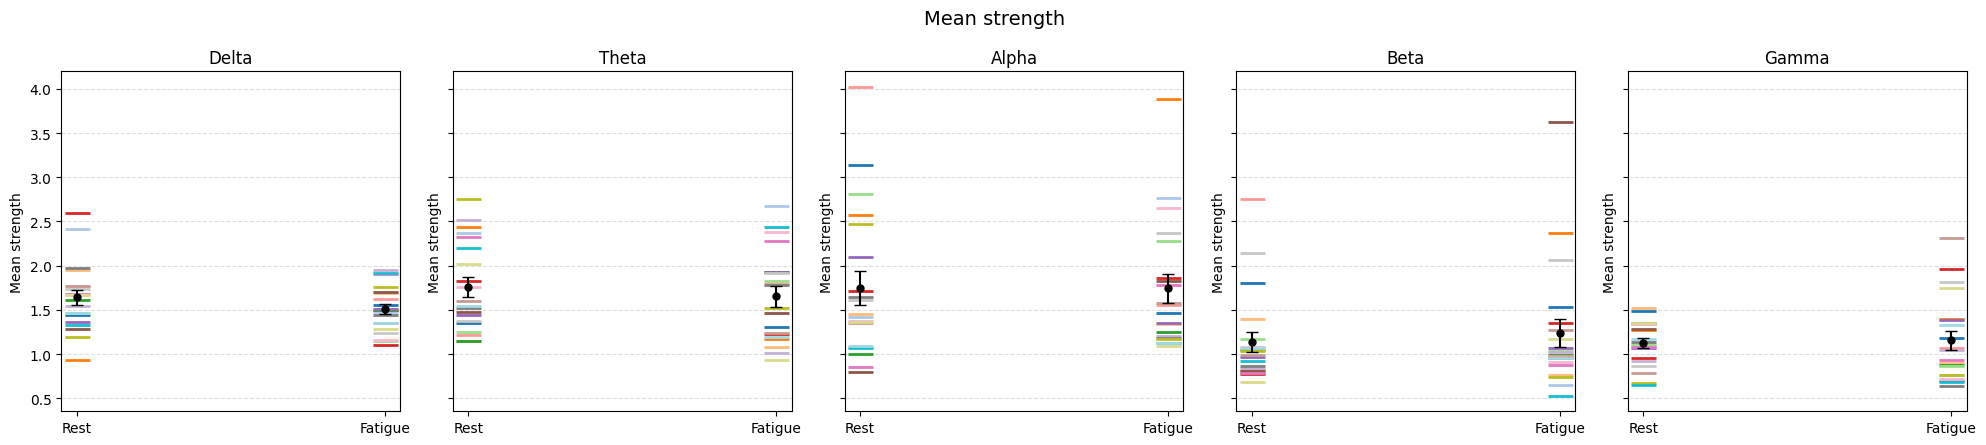

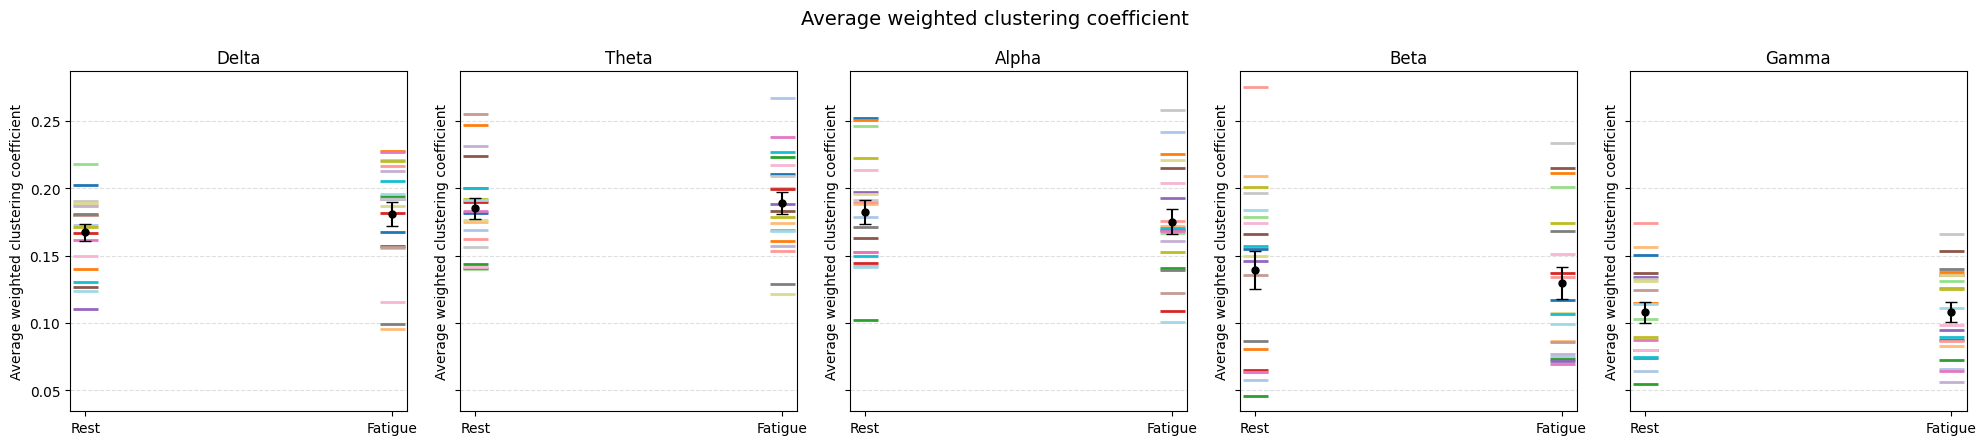

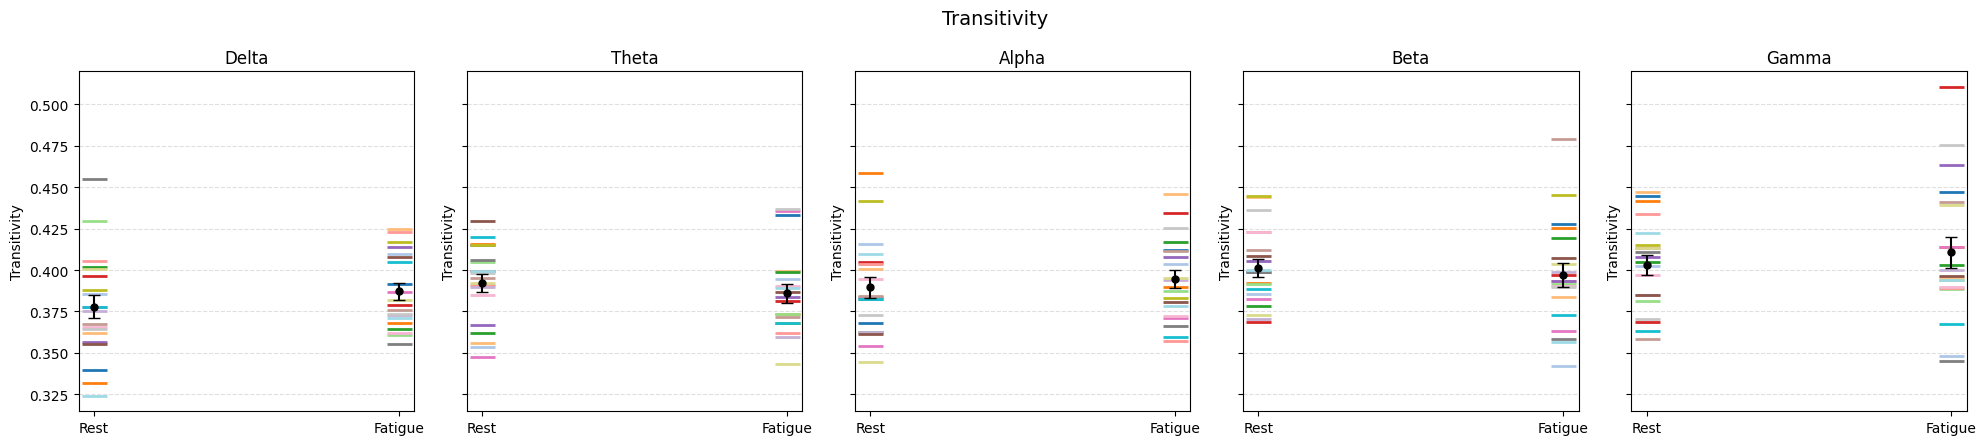

In [ ]:
def plot_global_metric_subjects(metric, ylabel, show_mean=True):
    fig, axes = plt.subplots(1, len(band_order), figsize=(20, 4.5), sharey=True)

    for ax, band in zip(axes, band_order):
        df_band = metrics_63_global_df[metrics_63_global_df["band"] == band]

        for subject_idx in range(1, N_SUBJECTS + 1):
            df_sub = df_band[df_band["subject"] == subject_idx].set_index("state")
            color = subject_colors[subject_idx - 1]

            if "rest" in df_sub.index:
                ax.plot(0, df_sub.loc["rest", metric], marker="_", markersize=18, linestyle="None", color=color, markeredgewidth=2)

            if "fatigue" in df_sub.index:
                ax.plot(1, df_sub.loc["fatigue", metric], marker="_", markersize=18, linestyle="None", color=color, markeredgewidth=2)

        if show_mean:
            summary = (
                df_band.groupby("state")[metric]
                .agg(["mean", "sem"])
                .reindex(state_order)
            )

            ax.errorbar(
                [0, 1],
                summary["mean"].values,
                yerr=summary["sem"].values,
                fmt="o",
                color="black",
                capsize=4,
                linewidth=1.5,
                markersize=5
            )

        ax.set_title(band.capitalize())
        ax.set_xticks([0, 1])
        ax.set_xticklabels(["Rest", "Fatigue"])
        ax.set_ylabel(ylabel)
        ax.grid(axis="y", linestyle="--", alpha=0.4)

    fig.suptitle(ylabel, fontsize=14)
    plt.tight_layout()
    plt.show()
plot_global_metric_subjects("mean_strength", "Mean strength")
plot_global_metric_subjects("average_weighted_clustering", "Average weighted clustering coefficient")
plot_global_metric_subjects("transitivity_unweighted", "Transitivity")

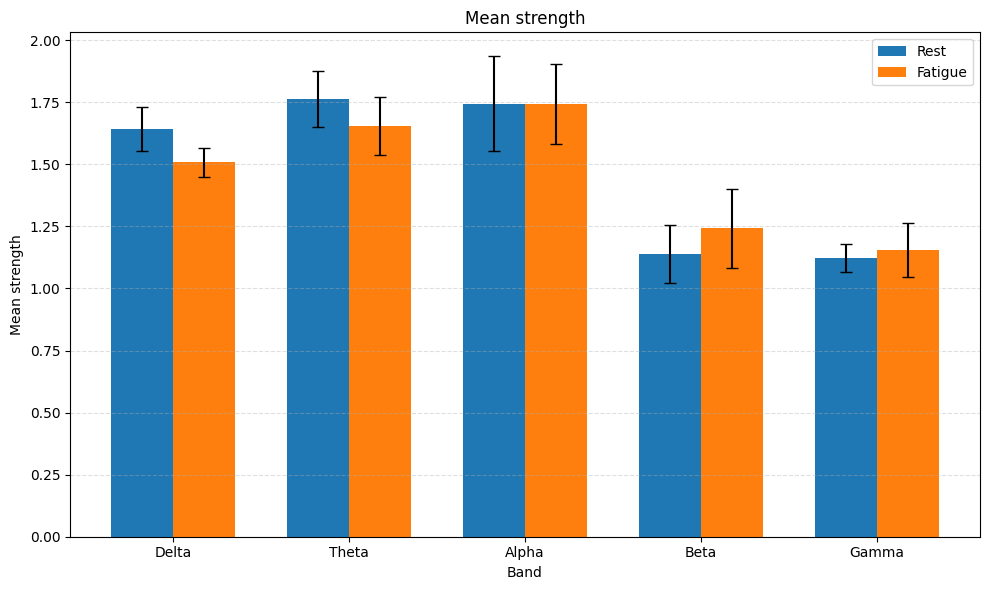

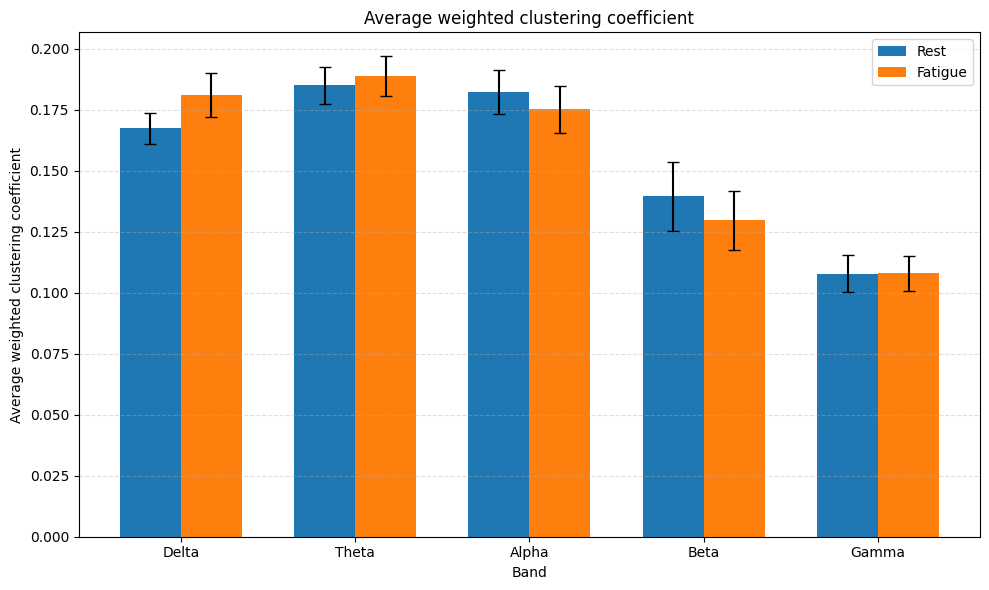

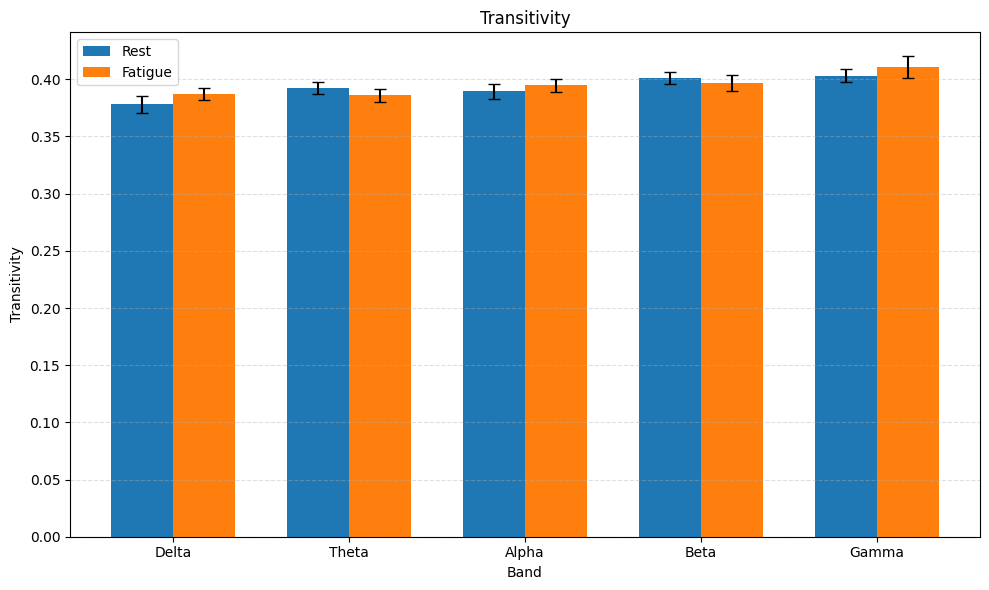

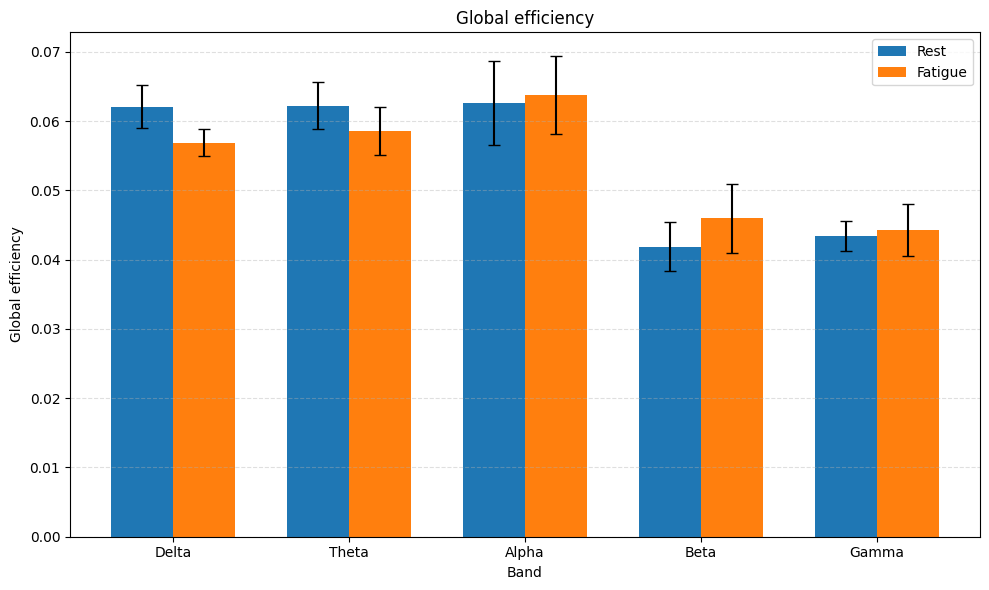

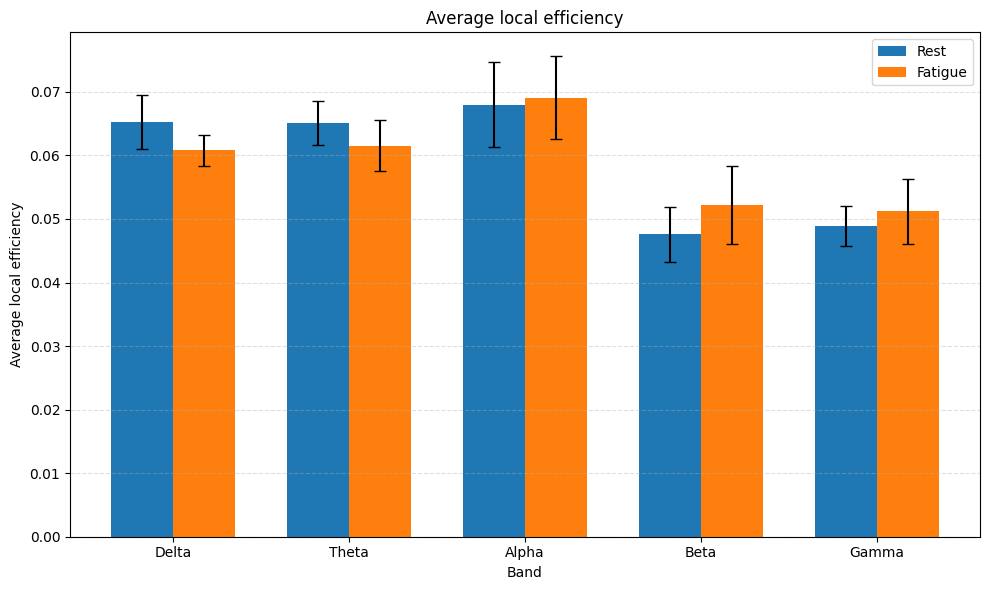

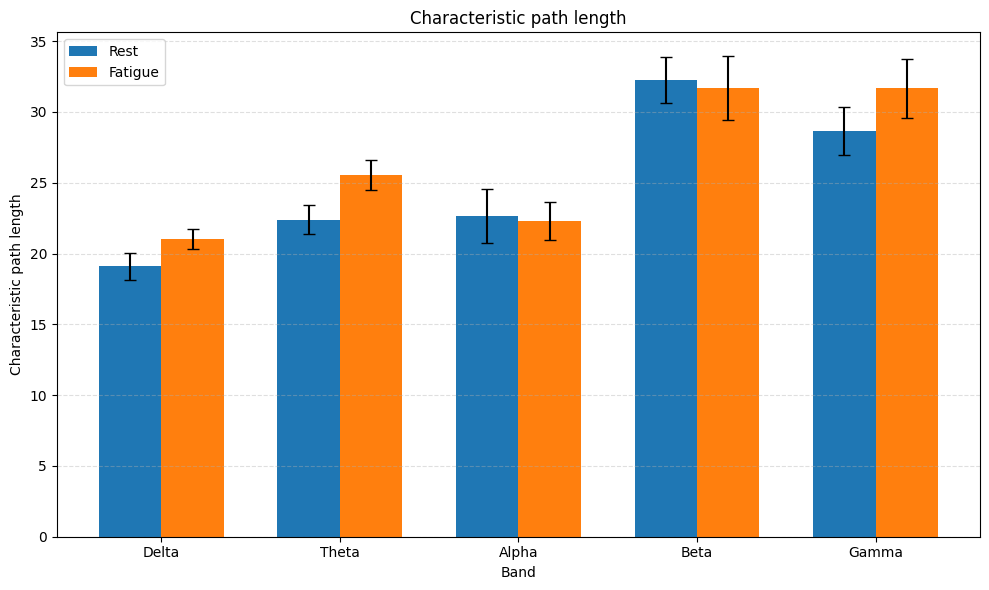

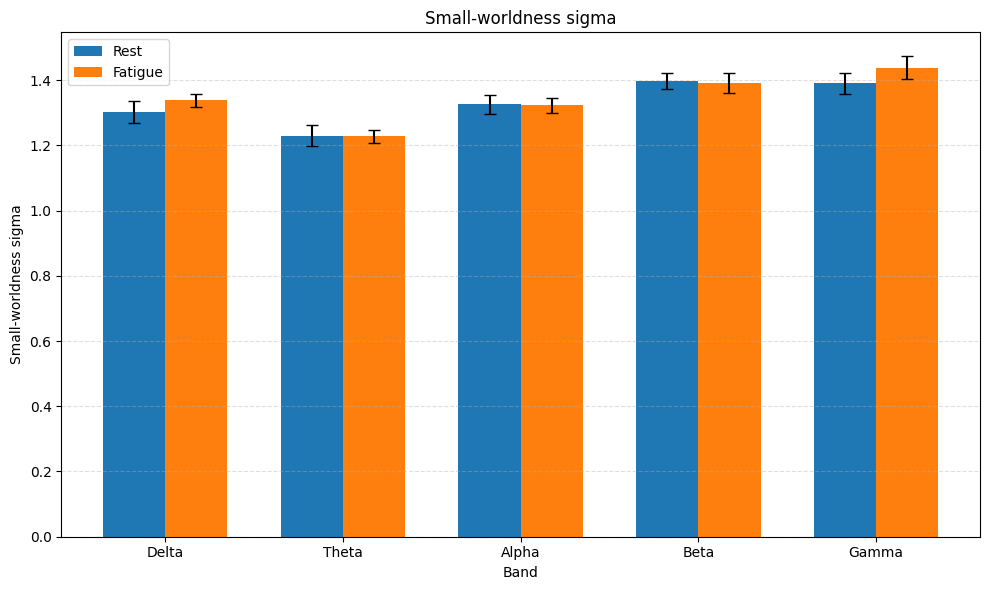

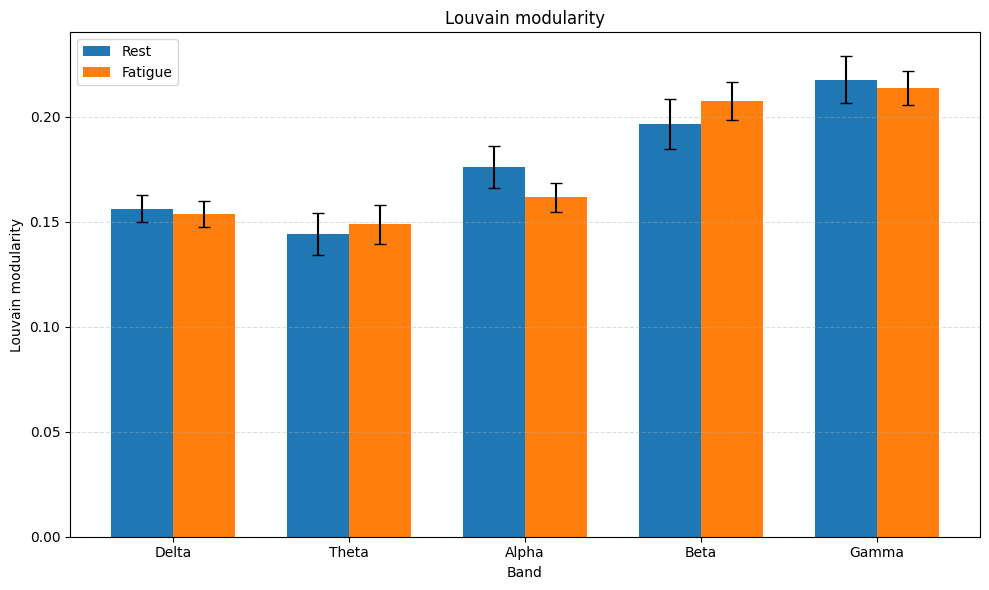

In [ ]:
state_order = ["rest", "fatigue"]
band_order = ["delta", "theta", "alpha", "beta", "gamma"]

def plot_global_metric_bars(metric, ylabel):
    summary = (
        metrics_63_global_df
        .groupby(["band", "state"])[metric]
        .agg(["mean", "sem"])
        .reset_index()
    )

    fig, ax = plt.subplots(figsize=(10, 6))

    x = np.arange(len(band_order))
    width = 0.35

    rest_vals = summary[summary["state"] == "rest"].set_index("band").reindex(band_order)
    fatigue_vals = summary[summary["state"] == "fatigue"].set_index("band").reindex(band_order)

    ax.bar(
        x - width/2,
        rest_vals["mean"],
        width,
        yerr=rest_vals["sem"],
        capsize=4,
        label="Rest"
    )

    ax.bar(
        x + width/2,
        fatigue_vals["mean"],
        width,
        yerr=fatigue_vals["sem"],
        capsize=4,
        label="Fatigue"
    )

    ax.set_xticks(x)
    ax.set_xticklabels([b.capitalize() for b in band_order])
    ax.set_xlabel("Band")
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout()
    plt.show()

plot_global_metric_bars("mean_strength", "Mean strength")
plot_global_metric_bars("average_weighted_clustering", "Average weighted clustering coefficient")
plot_global_metric_bars("transitivity_unweighted", "Transitivity")
plot_global_metric_bars("global_efficiency", "Global efficiency")
plot_global_metric_bars("average_local_efficiency", "Average local efficiency")
plot_global_metric_bars("characteristic_path_length", "Characteristic path length")
plot_global_metric_bars("smallworld_sigma", "Small-worldness sigma")
plot_global_metric_bars("louvain_modularity", "Louvain modularity")

/tmp/ipykernel_5628/2837694941.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["region", "state"], as_index=False)
/tmp/ipykernel_5628/2837694941.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["region", "state"], as_index=False)
/tmp/ipykernel_5628/2837694941.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["region", "state"], as_index=False)
/tmp/ipykernel_5628/2837694941.py:

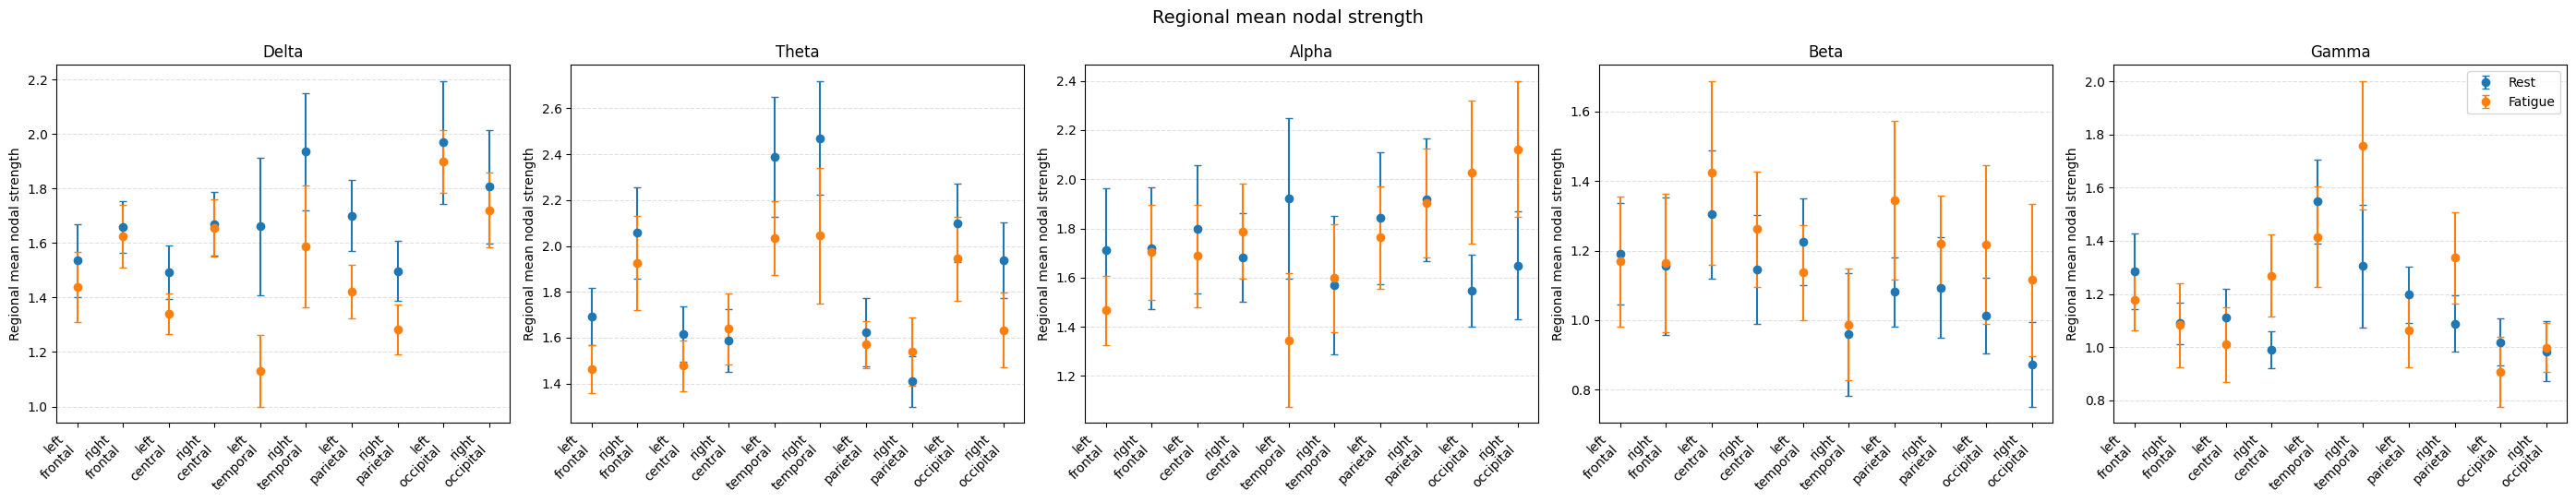

/tmp/ipykernel_5628/2837694941.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["region", "state"], as_index=False)
/tmp/ipykernel_5628/2837694941.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["region", "state"], as_index=False)
/tmp/ipykernel_5628/2837694941.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["region", "state"], as_index=False)
/tmp/ipykernel_5628/2837694941.py:

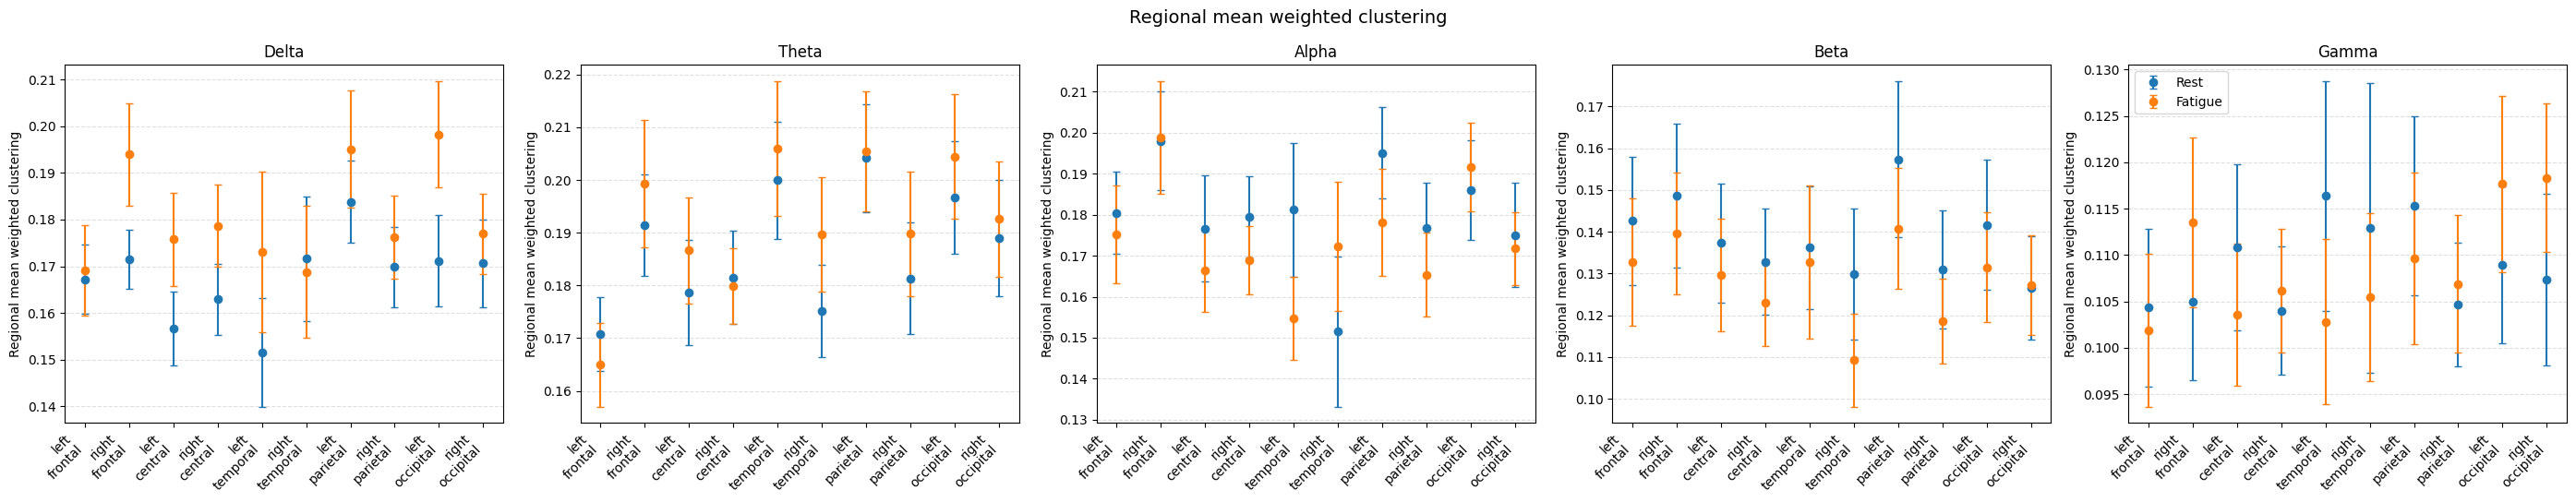

/tmp/ipykernel_5628/2837694941.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["region", "state"], as_index=False)
/tmp/ipykernel_5628/2837694941.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["region", "state"], as_index=False)
/tmp/ipykernel_5628/2837694941.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["region", "state"], as_index=False)
/tmp/ipykernel_5628/2837694941.py:

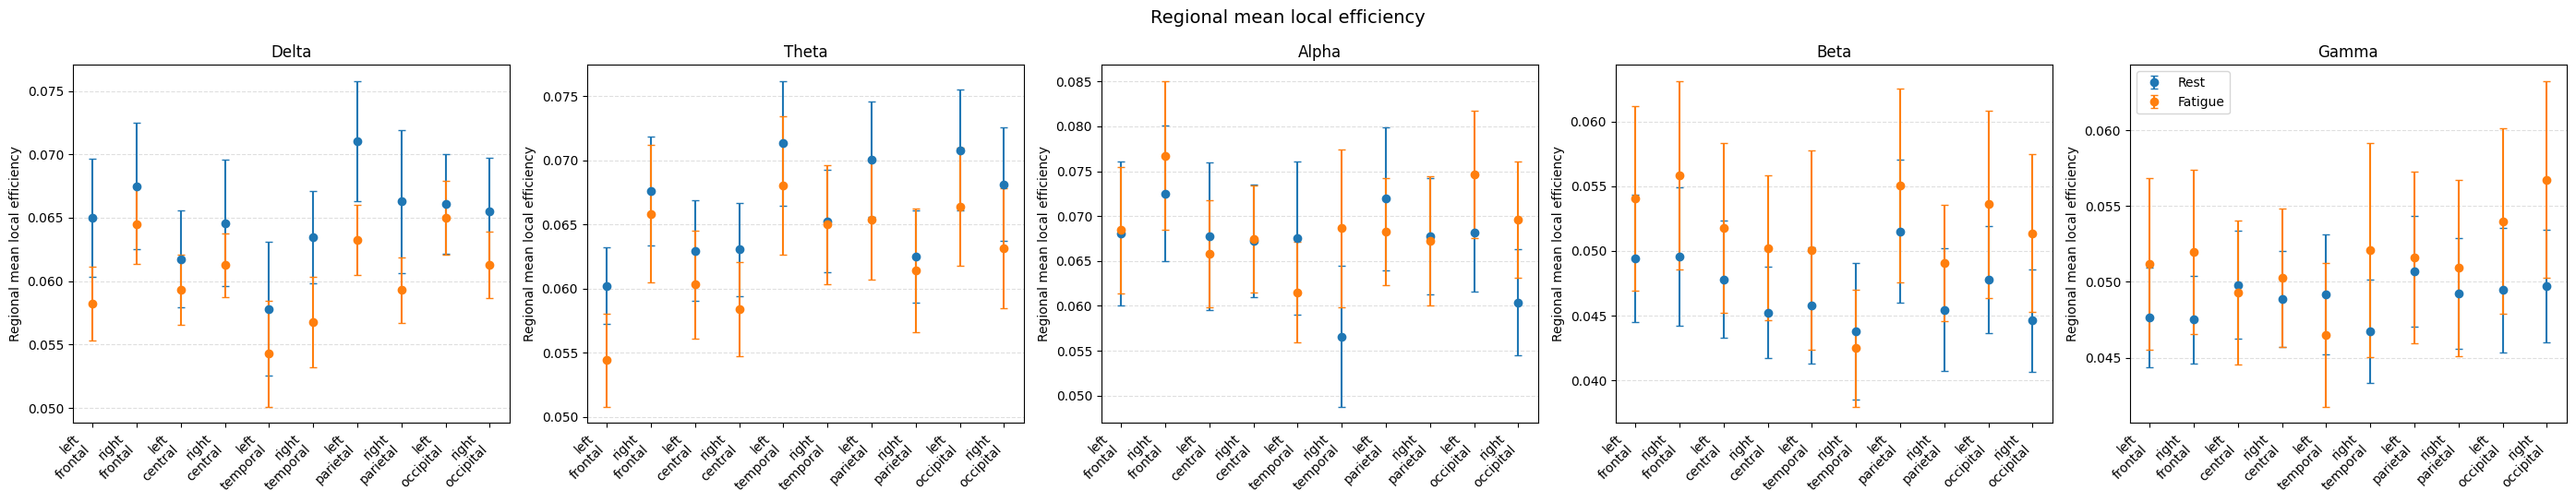

In [ ]:
def plot_regional_metric(metric, ylabel):
    fig, axes = plt.subplots(1, len(band_order), figsize=(28, 5.5))
    x = np.arange(len(region_names))
    region_labels = [region.replace("_", "\n") for region in region_names]

    for ax, band in zip(axes, band_order):
        summary = (
            regional_metrics_df[
                regional_metrics_df["band"] == band
            ]
            .groupby(["region", "state"], as_index=False)
            .agg(
                mean=(metric, "mean"),
                sem=(metric, "sem")
            )
        )

        for state in state_order:
            values = (
                summary[summary["state"] == state]
                .set_index("region")
                .reindex(region_names)
            )

            ax.errorbar(
                x,
                values["mean"],
                yerr=values["sem"],
                marker="o",
                linestyle="none",
                capsize=3,
                label=state_titles[state]
            )

        ax.set_title(band.capitalize())
        ax.set_xticks(x)
        ax.set_xticklabels(region_labels, rotation=45, ha="right")
        ax.set_ylabel(ylabel)
        ax.grid(axis="y", linestyle="--", alpha=0.4)

    axes[-1].legend()
    fig.suptitle(ylabel, fontsize=14)
    plt.tight_layout()
    plt.show()

plot_regional_metric(
    "strength",
    "Regional mean nodal strength"
)

plot_regional_metric(
    "weighted_clustering",
    "Regional mean weighted clustering"
)

plot_regional_metric(
    "local_efficiency",
    "Regional mean local efficiency"
)

# K-means


In [ ]:
electrode_positions = {
    row["labels"]: (-row["Y"], row["X"])
    for _, row in chanlocs.iterrows()
}

positions = {
    node: electrode_positions[labels[node]]
    for node in range(len(labels))
}

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

n_clusters = 5
kmeans_random_state = 42

def run_kmeans(A, G, n_clusters=10, random_state=42):
    X = StandardScaler().fit_transform(A)

    model = KMeans(
        n_clusters=n_clusters,
        n_init=20,
        random_state=random_state
    )

    cluster_labels = model.fit_predict(X)
    cluster_sizes = np.bincount(cluster_labels, minlength=n_clusters)

    communities = [
        set(np.where(cluster_labels == cluster_id)[0])
        for cluster_id in range(n_clusters)
    ]

    modularity = nx.community.modularity(G, communities, weight="weight")

    triu_i, triu_j = np.triu_indices(A.shape[0], k=1)
    edge_weights = A[triu_i, triu_j]
    same_cluster = cluster_labels[triu_i] == cluster_labels[triu_j]

    summary = {
        "n_clusters": n_clusters,
        "kmeans_inertia": model.inertia_, # How close electrodes are to the center of the cluster
        "kmeans_silhouette": silhouette_score(X, cluster_labels), # How distinct are the clusters?
        "kmeans_modularity": modularity,
        "cluster_size_min": cluster_sizes.min(),
        "cluster_size_max": cluster_sizes.max(),
        "cluster_size_std": cluster_sizes.std(),
        "mean_within_cluster_pli": edge_weights[same_cluster].mean(),
        "mean_between_cluster_pli": edge_weights[~same_cluster].mean()
    }

    return cluster_labels, cluster_sizes, summary

In [ ]:
import os
import matplotlib.pyplot as plt
import seaborn as sns
from mpl_toolkits.axes_grid1 import make_axes_locatable

subject_idx = 0
threshold_proportion = 0.30

one_subject_summary_rows = []
one_subject_label_rows = []
one_subject_kmeans = {}

for band in band_order:
    for state in state_order:
        state_path = os.path.join(base_path, state)
        file_path = os.path.join(state_path, files[state][band]["matrix"])

        data = np.load(file_path)
        A = data[subject_idx, :, :]
        A_thresholded = threshold_proportional_upper(A, threshold_proportion)

        G = build_graph_from_adjacency(A_thresholded, labels)
        G = add_distance_from_weight(G)

        cluster_labels, cluster_sizes, summary = run_kmeans(
            A_thresholded,
            G,
            n_clusters=n_clusters,
            random_state=kmeans_random_state
        )

        one_subject_kmeans[(state, band)] = {
            "A": A_thresholded,
            "cluster_labels": cluster_labels
        }

        one_subject_summary_rows.append({
            "subject": subject_idx + 1,
            "state": state,
            "band": band,
            "threshold_proportion": threshold_proportion,
            **summary
        })

        for node, cluster_id in enumerate(cluster_labels):
            one_subject_label_rows.append({
                "subject": subject_idx + 1,
                "state": state,
                "band": band,
                "electrode_index": node,
                "electrode": labels[node],
                "cluster": cluster_id,
                "cluster_size": cluster_sizes[cluster_id]
            })

one_subject_kmeans_summary_df = pd.DataFrame(one_subject_summary_rows)
one_subject_kmeans_labels_df = pd.DataFrame(one_subject_label_rows)

display(one_subject_kmeans_summary_df)
display(one_subject_kmeans_labels_df.head(20))

,subject,state,band,threshold_proportion,n_clusters,kmeans_inertia,kmeans_silhouette,kmeans_modularity,cluster_size_min,cluster_size_max,cluster_size_std,mean_within_cluster_pli,mean_between_cluster_pli
0,1,rest,delta,0.3,5,2545.137891,0.114536,-0.147944,4,24,6.945502,0.006199,0.028915
1,1,fatigue,delta,0.3,5,2451.038783,0.150634,-0.101782,3,32,10.051865,0.008879,0.032653
2,1,rest,theta,0.3,5,2500.177274,0.123665,0.015124,4,19,5.083306,0.023632,0.021313
3,1,fatigue,theta,0.3,5,2453.848408,0.173745,-0.102717,5,28,8.685620,0.010012,0.025512
4,1,rest,alpha,0.3,5,2449.839001,0.134709,-0.093788,6,28,7.989994,0.021984,0.061145
5,1,fatigue,alpha,0.3,5,2572.814804,0.109855,-0.113898,1,24,7.863841,0.011419,0.027991
6,1,rest,beta,0.3,5,2302.015619,0.178473,-0.024803,5,26,7.337575,0.020642,0.031951
7,1,fatigue,beta,0.3,5,2561.408596,0.129545,-0.025684,6,28,7.939773,0.016391,0.027709
8,1,rest,gamma,0.3,5,2344.043137,0.215291,-0.019998,1,38,13.305638,0.014712,0.030403
9,1,fatigue,gamma,0.3,5,2599.749479,0.107372,0.043842,4,21,6.711185,0.020602,0.018681


,subject,state,band,electrode_index,electrode,cluster,cluster_size
0,1,rest,delta,0,Fp1,3,7
1,1,rest,delta,1,AF7,3,7
2,1,rest,delta,2,AF3,3,7
3,1,rest,delta,3,F1,1,13
4,1,rest,delta,4,F3,4,24
5,1,rest,delta,5,F5,4,24
6,1,rest,delta,6,F7,4,24
7,1,rest,delta,7,FT7,2,4
8,1,rest,delta,8,FC5,2,4
9,1,rest,delta,9,FC3,4,24


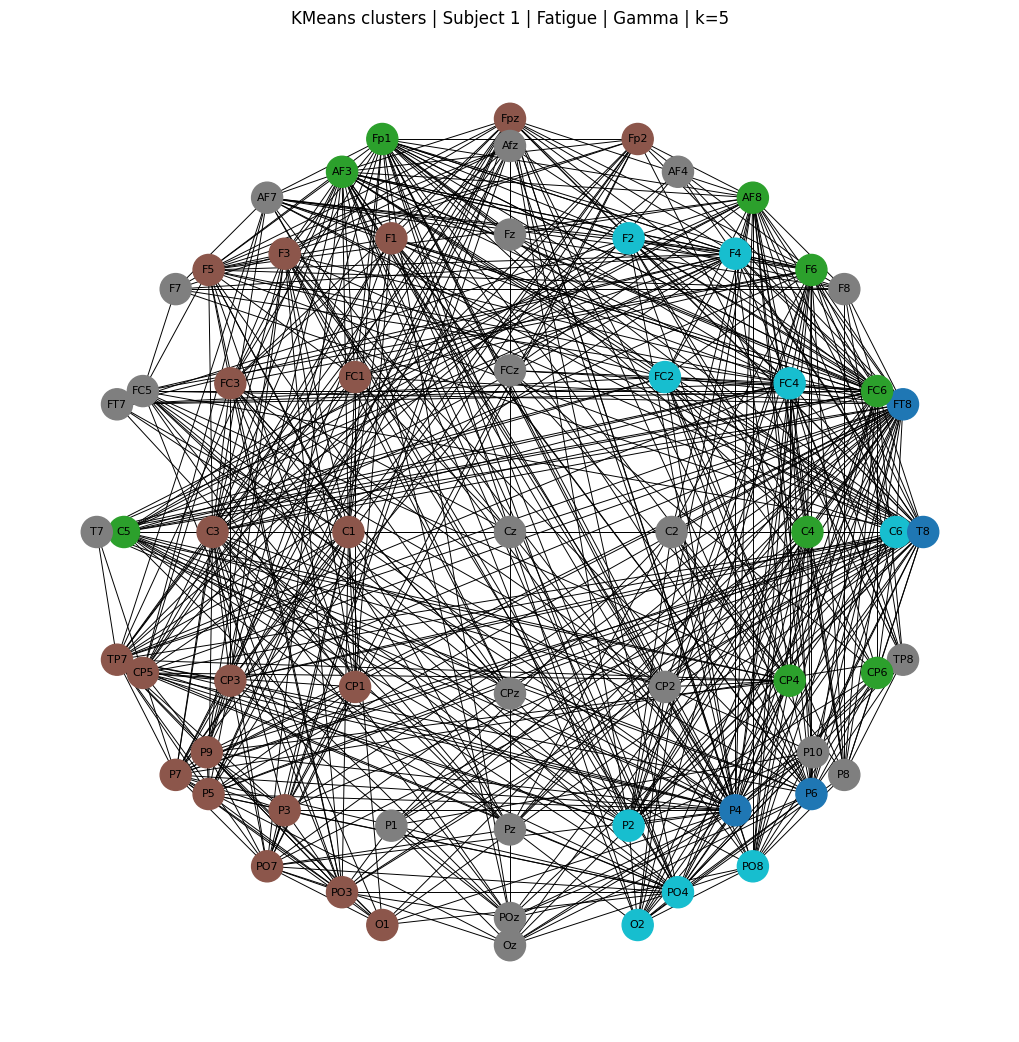

In [ ]:
node_labels = {
    node: labels[node]
    for node in G.nodes()
}

node_colors = [cluster_labels[node] for node in G.nodes()]

plt.figure(figsize=(10, 10))

nx.draw(
    G,
    pos=positions,
    node_color=node_colors,
    cmap=plt.cm.tab10,
    vmin=0,
    vmax=n_clusters - 1,
    with_labels=False,
    node_size=500,
    edge_color="black",
    width=0.7
)

nx.draw_networkx_labels(
    G,
    pos=positions,
    labels=node_labels,
    font_size=8
)

plt.gca().set_aspect("equal")
plt.title(
    f"KMeans clusters | Subject {subject_idx + 1} | "
    f"{state.capitalize()} | {band.capitalize()} | k={n_clusters}"
)
plt.show()

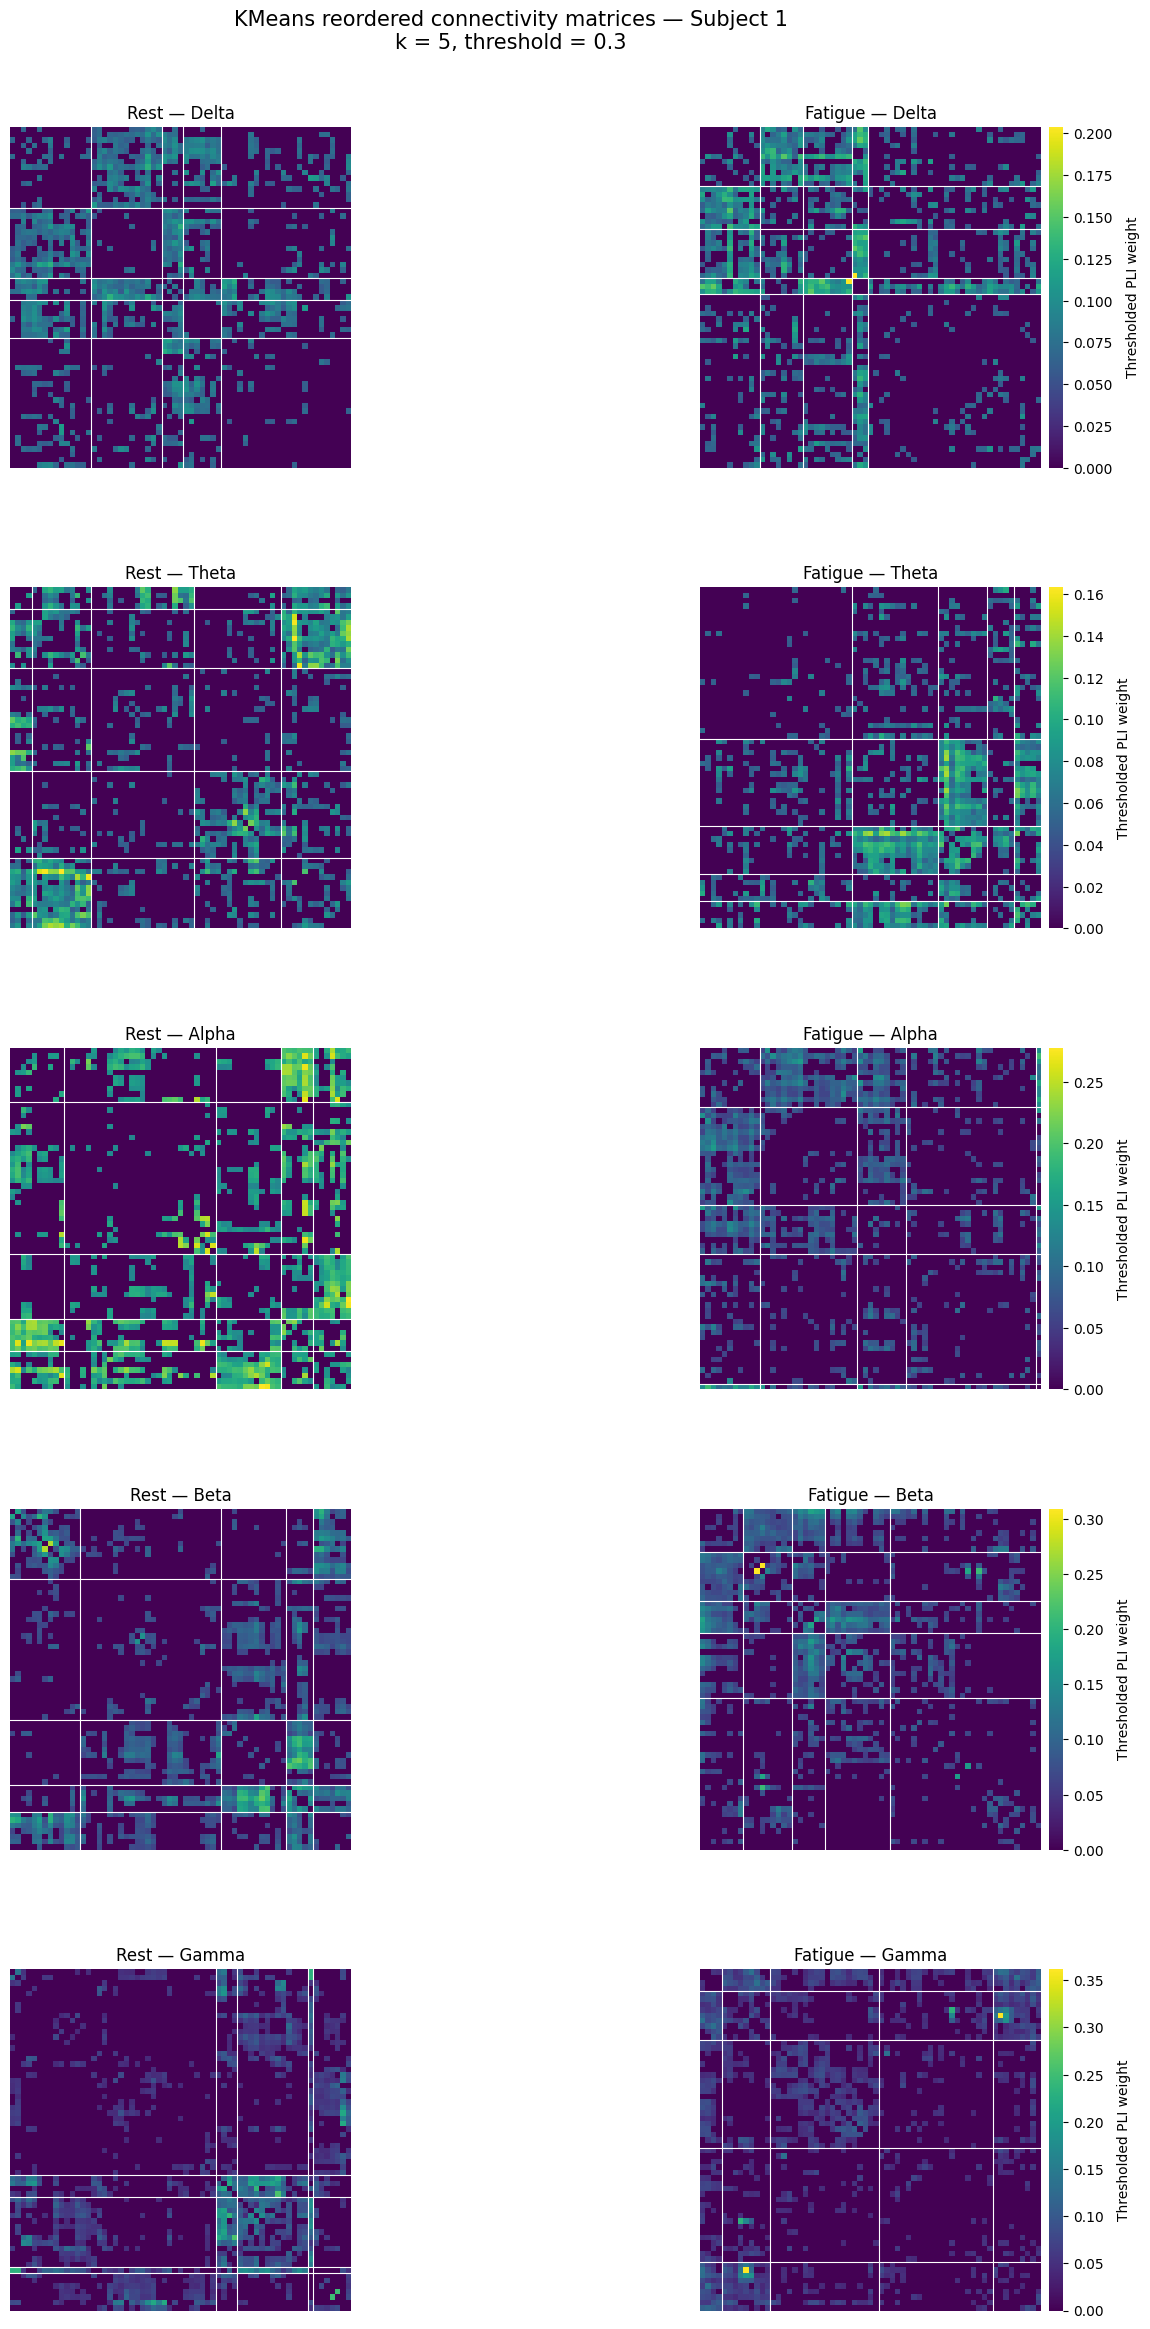

In [ ]:
fig, axes = plt.subplots(len(band_order), len(state_order), figsize=(16, 26))

for row_idx, band in enumerate(band_order):
    vmax = max(
        one_subject_kmeans[("rest", band)]["A"].max(),
        one_subject_kmeans[("fatigue", band)]["A"].max()
    )

    for col_idx, state in enumerate(state_order):
        ax = axes[row_idx, col_idx]

        A = one_subject_kmeans[(state, band)]["A"]
        cluster_labels = one_subject_kmeans[(state, band)]["cluster_labels"]

        order = np.argsort(cluster_labels, kind="stable")
        A_sorted = A[np.ix_(order, order)]

        show_cbar = state == "fatigue"

        if show_cbar:
            divider = make_axes_locatable(ax)
            cax = divider.append_axes("right", size="4%", pad=0.08)
        else:
            cax = None

        sns.heatmap(
            A_sorted,
            ax=ax,
            cmap="viridis",
            vmin=0,
            vmax=vmax,
            square=True,
            cbar=show_cbar,
            cbar_ax=cax,
            xticklabels=False,
            yticklabels=False
        )

        boundaries = np.where(np.diff(cluster_labels[order]) != 0)[0] + 1

        for boundary in boundaries:
            ax.axhline(boundary, color="white", linewidth=0.8)
            ax.axvline(boundary, color="white", linewidth=0.8)

        ax.set_title(f"{state.capitalize()} — {band.capitalize()}")

        if show_cbar:
            cax.set_ylabel("Thresholded PLI weight", rotation=90, labelpad=10)

fig.suptitle(
    f"KMeans reordered connectivity matrices — Subject {subject_idx + 1}\n"
    f"k = {n_clusters}, threshold = {threshold_proportion}",
    fontsize=15,
    y=0.995
)

fig.subplots_adjust(top=0.95, hspace=0.35, wspace=0.30)
plt.show()

In [ ]:
import os
import numpy as np
import pandas as pd

k_values = [3, 5, 7, 9]
threshold_proportion = 0.30
kmeans_random_state = 42

results_path = os.path.join(save_path, "kmeans")
os.makedirs(results_path, exist_ok=True)

kmeans_rows = []

for state, bands in files.items():
    state_path = os.path.join(base_path, state)

    for band, representations in bands.items():
        file_path = os.path.join(state_path, representations["matrix"])
        data = np.load(file_path)

        print(f"Processing: {state} | {band}")

        for subject_idx in range(N_SUBJECTS):
            A = data[subject_idx, :, :]
            A_thresholded = threshold_proportional_upper(A, threshold_proportion)
            G = build_graph_from_adjacency(A_thresholded, labels)
            G = add_distance_from_weight(G)

            for n_clusters in k_values:
                cluster_labels, cluster_sizes, summary = run_kmeans(
                    A_thresholded,
                    G,
                    n_clusters=n_clusters,
                    random_state=kmeans_random_state
                )

                within_between_difference = (
                    summary["mean_within_cluster_pli"] -
                    summary["mean_between_cluster_pli"]
                )

                kmeans_rows.append({
                    "subject": subject_idx + 1,
                    "state": state,
                    "band": band,
                    "threshold_proportion": threshold_proportion,
                    **summary,
                    "within_between_difference": within_between_difference,
                    "n_singleton_clusters": int(np.sum(cluster_sizes == 1))
                })

kmeans_comparison_df = pd.DataFrame(kmeans_rows)

kmeans_comparison_df = kmeans_comparison_df.sort_values(
    ["n_clusters", "subject", "state", "band"]
).reset_index(drop=True)

output_file = os.path.join(
    results_path,
    "kmeans_comparison_k3_k5_k7_k9_thr_0.30.csv"
)

kmeans_comparison_df.to_csv(output_file, index=False)

print(kmeans_comparison_df.shape)
print(output_file)

display(kmeans_comparison_df.head())

Processing: fatigue | delta
Processing: fatigue | theta
Processing: fatigue | alpha
Processing: fatigue | beta
Processing: fatigue | gamma
Processing: rest | delta
Processing: rest | theta
Processing: rest | alpha
Processing: rest | beta
Processing: rest | gamma
(800, 15)
/content/drive/MyDrive/1. Thesis Project/Vivian Thanou Thesis/401 PLI networks/kmeans/kmeans_comparison_k3_k5_k7_k9_thr_0.30.csv


,subject,state,band,threshold_proportion,n_clusters,kmeans_inertia,kmeans_silhouette,kmeans_modularity,cluster_size_min,cluster_size_max,cluster_size_std,mean_within_cluster_pli,mean_between_cluster_pli,within_between_difference,n_singleton_clusters
0,1,fatigue,alpha,0.3,3,2941.835523,0.126979,-0.097119,12,30,7.348469,0.016336,0.027725,-0.011388,0
1,1,fatigue,beta,0.3,3,3009.562699,0.135287,-0.009664,14,33,8.524475,0.021272,0.026752,-0.005480,0
2,1,fatigue,delta,0.3,3,2930.682253,0.184681,-0.149745,3,46,18.239152,0.012215,0.042825,-0.030609,0
3,1,fatigue,gamma,0.3,3,3114.233194,0.114815,0.054715,11,32,8.602325,0.019591,0.018882,0.000709,0
4,1,fatigue,theta,0.3,3,2918.259101,0.156311,-0.096129,13,31,7.483315,0.014234,0.025081,-0.010847,0


# CPM

In [ ]:
from networkx.algorithms.community import k_clique_communities

def run_cpm(G, A, clique_size):
    communities = [set(community) for community in k_clique_communities(G, clique_size)]

    n_nodes = G.number_of_nodes()
    membership_counts = np.zeros(n_nodes, dtype=int)
    shared_community = np.zeros((n_nodes, n_nodes), dtype=bool)

    for community in communities:
        nodes = np.array(sorted(community), dtype=int)
        membership_counts[nodes] += 1
        shared_community[np.ix_(nodes, nodes)] = True

    np.fill_diagonal(shared_community, False)

    community_sizes = np.array([len(community) for community in communities], dtype=float)
    covered_nodes = membership_counts > 0

    triu_i, triu_j = np.triu_indices(n_nodes, k=1)
    pair_weights = A[triu_i, triu_j]
    same_community = shared_community[triu_i, triu_j]

    within_weights = pair_weights[same_community]
    noncommunity_weights = pair_weights[~same_community]

    mean_within_pli = np.mean(within_weights) if len(within_weights) > 0 else np.nan
    mean_noncommunity_pli = np.mean(noncommunity_weights) if len(noncommunity_weights) > 0 else np.nan

    summary = {
        "cpm_k": clique_size,
        "cpm_n_communities": len(communities),
        "cpm_n_covered_nodes": int(np.sum(covered_nodes)),
        "cpm_n_unassigned_nodes": int(np.sum(~covered_nodes)),
        "cpm_coverage_fraction": np.mean(covered_nodes),
        "cpm_n_overlapping_nodes": int(np.sum(membership_counts > 1)),
        "cpm_overlap_fraction_all_nodes": np.mean(membership_counts > 1),
        "cpm_overlap_fraction_covered_nodes": (
            np.mean(membership_counts[covered_nodes] > 1)
            if np.sum(covered_nodes) > 0 else np.nan
        ),
        "cpm_mean_memberships_per_covered_node": (
            np.mean(membership_counts[covered_nodes])
            if np.sum(covered_nodes) > 0 else np.nan
        ),
        "cpm_mean_community_size": np.mean(community_sizes) if len(community_sizes) > 0 else np.nan,
        "cpm_min_community_size": np.min(community_sizes) if len(community_sizes) > 0 else np.nan,
        "cpm_max_community_size": np.max(community_sizes) if len(community_sizes) > 0 else np.nan,
        "cpm_community_size_std": np.std(community_sizes) if len(community_sizes) > 0 else np.nan,
        "cpm_largest_community_fraction": (
            np.max(community_sizes) / n_nodes
            if len(community_sizes) > 0 else np.nan
        ),
        "cpm_mean_within_community_pli": mean_within_pli,
        "cpm_mean_noncommunity_pli": mean_noncommunity_pli,
        "cpm_within_noncommunity_difference": (
            mean_within_pli - mean_noncommunity_pli
            if not np.isnan(mean_within_pli) and not np.isnan(mean_noncommunity_pli)
            else np.nan
        )
    }

    return communities, membership_counts, summary

In [ ]:
import os
import numpy as np
import pandas as pd

clique_sizes = [3, 5, 7, 9]
threshold_proportion = 0.30

results_path = os.path.join(save_path, "CPM")
os.makedirs(results_path, exist_ok=True)

cpm_summary_rows = []
cpm_node_rows = []
cpm_membership_rows = []

for state, bands in files.items():
    state_path = os.path.join(base_path, state)

    for band, representations in bands.items():
        file_path = os.path.join(state_path, representations["matrix"])
        data = np.load(file_path)

        print(f"Processing: {state} | {band}")

        for subject_idx in range(N_SUBJECTS):
            A = data[subject_idx, :, :]
            A_thresholded = threshold_proportional_upper(A, threshold_proportion)
            G = build_graph_from_adjacency(A_thresholded, labels)

            for clique_size in clique_sizes:
                communities, membership_counts, summary = run_cpm(
                    G,
                    A_thresholded,
                    clique_size
                )

                cpm_summary_rows.append({
                    "subject": subject_idx + 1,
                    "state": state,
                    "band": band,
                    "threshold_proportion": threshold_proportion,
                    **summary
                })

                for node, membership_count in enumerate(membership_counts):
                    cpm_node_rows.append({
                        "subject": subject_idx + 1,
                        "state": state,
                        "band": band,
                        "cpm_k": clique_size,
                        "electrode_index": node,
                        "electrode": labels[node],
                        "membership_count": membership_count
                    })

                for community_id, community in enumerate(communities):
                    for node in sorted(community):
                        cpm_membership_rows.append({
                            "subject": subject_idx + 1,
                            "state": state,
                            "band": band,
                            "cpm_k": clique_size,
                            "community_id": community_id,
                            "electrode_index": node,
                            "electrode": labels[node],
                            "membership_count": membership_counts[node]
                        })

cpm_summary_df = pd.DataFrame(cpm_summary_rows)
cpm_node_membership_df = pd.DataFrame(cpm_node_rows)
cpm_community_members_df = pd.DataFrame(cpm_membership_rows)

cpm_summary_df = cpm_summary_df.sort_values(
    ["cpm_k", "subject", "state", "band"]
).reset_index(drop=True)

cpm_node_membership_df = cpm_node_membership_df.sort_values(
    ["cpm_k", "subject", "state", "band", "electrode_index"]
).reset_index(drop=True)

cpm_community_members_df = cpm_community_members_df.sort_values(
    ["cpm_k", "subject", "state", "band", "community_id", "electrode_index"]
).reset_index(drop=True)

summary_file = os.path.join(results_path, "cpm_summary_k3_k5_k7_k9_thr_0.30.csv")
node_file = os.path.join(results_path, "cpm_node_membership_counts_k3_k5_k7_k9_thr_0.30.csv")
membership_file = os.path.join(results_path, "cpm_community_memberships_k3_k5_k7_k9_thr_0.30.csv")

cpm_summary_df.to_csv(summary_file, index=False)
cpm_node_membership_df.to_csv(node_file, index=False)
cpm_community_members_df.to_csv(membership_file, index=False)

print(cpm_summary_df.shape)
print(cpm_node_membership_df.shape)
print(cpm_community_members_df.shape)

display(cpm_summary_df.head())

Processing: fatigue | delta
Processing: fatigue | theta
Processing: fatigue | alpha
Processing: fatigue | beta
Processing: fatigue | gamma
Processing: rest | delta
Processing: rest | theta
Processing: rest | alpha
Processing: rest | beta
Processing: rest | gamma
(800, 21)
(50400, 7)
(28201, 8)


,subject,state,band,threshold_proportion,cpm_k,cpm_n_communities,cpm_n_covered_nodes,cpm_n_unassigned_nodes,cpm_coverage_fraction,cpm_n_overlapping_nodes,...,cpm_overlap_fraction_covered_nodes,cpm_mean_memberships_per_covered_node,cpm_mean_community_size,cpm_min_community_size,cpm_max_community_size,cpm_community_size_std,cpm_largest_community_fraction,cpm_mean_within_community_pli,cpm_mean_noncommunity_pli,cpm_within_noncommunity_difference
0,1,fatigue,alpha,0.3,3,1,61,2,0.968254,0,...,0.0,1.0,61.0,61.0,61.0,0.0,0.968254,0.025103,0.000905,0.024198
1,1,fatigue,beta,0.3,3,1,61,2,0.968254,0,...,0.0,1.0,61.0,61.0,61.0,0.0,0.968254,0.026304,0.000487,0.025817
2,1,fatigue,delta,0.3,3,1,60,3,0.952381,0,...,0.0,1.0,60.0,60.0,60.0,0.0,0.952381,0.027561,0.001617,0.025944
3,1,fatigue,gamma,0.3,3,1,62,1,0.984127,0,...,0.0,1.0,62.0,62.0,62.0,0.0,0.984127,0.019728,0.001548,0.018180
4,1,fatigue,theta,0.3,3,1,61,2,0.968254,0,...,0.0,1.0,61.0,61.0,61.0,0.0,0.968254,0.022445,0.001323,0.021122


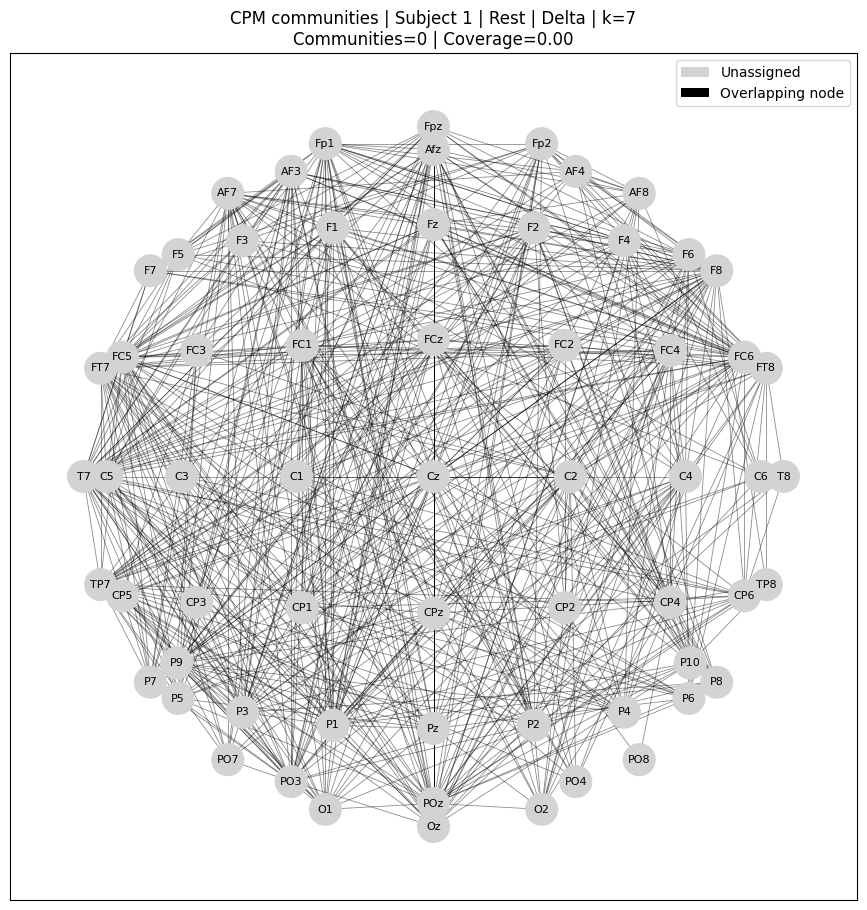

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

subject_idx = 0
state = "rest"
band = "delta"
clique_size = 7
threshold_proportion = 0.30

file_path = os.path.join(base_path, state, files[state][band]["matrix"])
data = np.load(file_path)

A = data[subject_idx, :, :]
A_thresholded = threshold_proportional_upper(A, threshold_proportion)
G = build_graph_from_adjacency(A_thresholded, labels)

communities, membership_counts, summary = run_cpm(
    G,
    A_thresholded,
    clique_size
)

node_community_ids = [[] for _ in range(len(labels))]

for community_id, community in enumerate(communities):
    for node in community:
        node_community_ids[node].append(community_id)

palette = plt.cm.tab20(np.linspace(0, 1, max(len(communities), 1)))
node_colors = []

for node in G.nodes():
    memberships = node_community_ids[node]

    if len(memberships) == 0:
        node_colors.append("lightgray")
    elif len(memberships) == 1:
        node_colors.append(palette[memberships[0]])
    else:
        node_colors.append("black")

node_labels = {node: labels[node] for node in G.nodes()}

plt.figure(figsize=(11, 11))

nx.draw_networkx_edges(
    G,
    pos=positions,
    edge_color="black",
    width=0.6,
    alpha=0.45
)

nx.draw_networkx_nodes(
    G,
    pos=positions,
    node_color=node_colors,
    node_size=520
)

nx.draw_networkx_labels(
    G,
    pos=positions,
    labels=node_labels,
    font_size=8
)

legend_items = [
    Patch(facecolor="lightgray", label="Unassigned"),
    Patch(facecolor="black", label="Overlapping node")
]

plt.legend(handles=legend_items, loc="upper right")
plt.gca().set_aspect("equal")

plt.title(
    f"CPM communities | Subject {subject_idx + 1} | "
    f"{state.capitalize()} | {band.capitalize()} | k={clique_size}\n"
    f"Communities={summary['cpm_n_communities']} | "
    f"Coverage={summary['cpm_coverage_fraction']:.2f}"
)

plt.show()

for community_id, community in enumerate(communities):
    community_labels = [labels[node] for node in sorted(community)]
    print(f"Community {community_id + 1}: {community_labels}")

# Main function for One Subject

In [ ]:
def compute_graph_metrics(A, labels, state, band, subject_idx, threshold_proportion=0.30, k_values=[3, 4, 5]):
    """
    Computes all graph metrics for one subject, one band, one state.
    """

    A_thresholded = threshold_proportional_upper(A, threshold_proportion)
    G_pos = build_graph_from_adjacency(A_thresholded, labels)
    G_pos = add_distance_from_weight(G_pos)

    metrics = {}

    metrics["state"] = state
    metrics["band"] = band
    metrics["subject"] = subject_idx + 1
    metrics["threshold_proportion"] = threshold_proportion
    metrics["n_nodes"] = G_pos.number_of_nodes()

    metrics["n_edges_all"] = G_pos.number_of_edges()
    metrics["density_all"] = nx.density(G_pos)

    metrics["n_edges_positive"] = G_pos.number_of_edges()
    metrics["density_positive"] = nx.density(G_pos)

    metrics["is_connected_positive"] = nx.is_connected(G_pos)

    # Degree
    degrees = dict(G_pos.degree())

    metrics["mean_degree"] = np.mean(list(degrees.values()))
    metrics["std_degree"] = np.std(list(degrees.values()))
    metrics["min_degree"] = np.min(list(degrees.values()))
    metrics["max_degree"] = np.max(list(degrees.values()))

    # Strength = weighted degree
    strengths = dict(G_pos.degree(weight="weight"))

    metrics["mean_strength"] = np.mean(list(strengths.values()))
    metrics["std_strength"] = np.std(list(strengths.values()))
    metrics["min_strength"] = np.min(list(strengths.values()))
    metrics["max_strength"] = np.max(list(strengths.values()))

    # Path length
    if nx.is_connected(G_pos):
        metrics["path_length"] = nx.average_shortest_path_length(
            G_pos,
            weight="distance"
        )

        metrics["path_length_lcc"] = metrics["path_length"]
        metrics["lcc_n_nodes"] = G_pos.number_of_nodes()

    else:
        largest_cc = max(nx.connected_components(G_pos), key=len)
        G_lcc = G_pos.subgraph(largest_cc).copy()

        metrics["path_length"] = np.nan

        metrics["path_length_lcc"] = nx.average_shortest_path_length(
            G_lcc,
            weight="distance"
        )

        metrics["lcc_n_nodes"] = G_lcc.number_of_nodes()

    # Efficiency
    metrics["global_efficiency_weighted"] = weighted_global_efficiency(
        G_pos,
        distance="distance"
    )

    metrics["local_efficiency_weighted"] = weighted_local_efficiency(
        G_pos,
        distance="distance"
    )

    # Small-worldness
    C, L, C_random, L_random, sigma = small_worldness_sigma(
        G_pos,
        n_random=20,
        seed=42
    )

    metrics["smallworld_C"] = C
    metrics["smallworld_L"] = L
    metrics["smallworld_C_random"] = C_random
    metrics["smallworld_L_random"] = L_random
    metrics["smallworld_sigma"] = sigma

    # Triangles
    triangles_per_node = nx.triangles(G_pos)

    metrics["total_triangles"] = sum(triangles_per_node.values()) / 3
    metrics["mean_triangles_per_node"] = np.mean(list(triangles_per_node.values()))
    metrics["std_triangles_per_node"] = np.std(list(triangles_per_node.values()))

    # Clustering coefficient
    clustering_unweighted = nx.clustering(G_pos)

    metrics["mean_clustering"] = np.mean(list(clustering_unweighted.values()))
    metrics["std_clustering"] = np.std(list(clustering_unweighted.values()))

    clustering_weighted = nx.clustering(G_pos, weight="weight")

    metrics["mean_weighted_clustering"] = np.mean(list(clustering_weighted.values()))
    metrics["std_weighted_clustering"] = np.std(list(clustering_weighted.values()))

    # Modularity: KMeans and Spectral for k = 3, 4, 5
    for k in k_values:

        mod_kmeans, labels_kmeans, communities_kmeans, sizes_kmeans = kmeans_modularity(
            A,
            G_pos,
            k
        )

        metrics[f"modularity_kmeans_k{k}"] = mod_kmeans
        metrics[f"n_communities_kmeans_k{k}"] = len(communities_kmeans)

        mod_spectral, labels_spectral, communities_spectral, sizes_spectral = spectral_modularity(
            A,
            G_pos,
            k
        )

        metrics[f"modularity_spectral_k{k}"] = mod_spectral
        metrics[f"n_communities_spectral_k{k}"] = len(communities_spectral)

    # Modularity: Anatomical region + hemisphere
    mod_anat_10, labels_anat_10, communities_anat_10, sizes_anat_10, group_names_anat_10, group_to_id_anat_10 = anatomical_region_hemisphere_modularity(
        A,
        G_pos,
        labels,
        midline_assignment="both_split"
    )

    metrics["modularity_anatomical_region_hemisphere_k10"] = mod_anat_10
    metrics["n_communities_anatomical_region_hemisphere"] = len(communities_anat_10)

    return metrics

In [ ]:
cluster_labels, group_names, group_to_id = anatomical_region_hemisphere_cluster_labels(
    labels,
    midline_assignment="both_split"
)

groups_df = pd.DataFrame({
    "electrode": labels,
    "group": group_names,
    "cluster_id": cluster_labels
})

for group in sorted(groups_df["group"].unique()):
    electrodes = groups_df.loc[groups_df["group"] == group, "electrode"].tolist()
    print(f"\n{group} - {len(electrodes)} electrodes")
    print(electrodes)

print("\nNumber of groups:", groups_df["group"].nunique())


left_central - 7 electrodes
['C1', 'C3', 'C5', 'CP5', 'CP3', 'CP1', 'Cz']

left_frontal - 12 electrodes
['Fp1', 'AF7', 'AF3', 'F1', 'F3', 'F5', 'F7', 'FC5', 'FC3', 'FC1', 'Fpz', 'Fz']

left_occipital - 2 electrodes
['O1', 'Oz']

left_parietal - 8 electrodes
['P1', 'P3', 'P5', 'P7', 'P9', 'PO7', 'PO3', 'Pz']

left_temporal - 3 electrodes
['FT7', 'T7', 'TP7']

right_central - 7 electrodes
['CPz', 'C2', 'C4', 'C6', 'CP6', 'CP4', 'CP2']

right_frontal - 12 electrodes
['Fp2', 'AF8', 'AF4', 'Afz', 'F2', 'F4', 'F6', 'F8', 'FC6', 'FC4', 'FC2', 'FCz']

right_occipital - 1 electrodes
['O2']

right_parietal - 8 electrodes
['POz', 'P2', 'P4', 'P6', 'P8', 'P10', 'PO8', 'PO4']

right_temporal - 3 electrodes
['FT8', 'T8', 'TP8']

Number of groups: 10


# test and Loop

In [ ]:
state = "rest"
band = "theta"
subject_idx = 0

matrix_filename = files[state][band]["matrix"]
matrix_path = os.path.join(base_path, state, matrix_filename)

pli_matrix_all = np.load(matrix_path)

A = pli_matrix_all[subject_idx, :, :]

test_metrics = compute_graph_metrics(
    A=A,
    labels=labels,
    state=state,
    band=band,
    subject_idx=subject_idx
)

test_df = pd.DataFrame([test_metrics])
test_df.T

,0
state,rest
band,theta
subject,1
threshold_proportion,0.3
n_nodes,63
n_edges_all,1950
density_all,0.998464
n_edges_positive,1950
density_positive,0.998464
is_connected_positive,True


In [ ]:
output_dir = "/content/drive/MyDrive/1. Thesis Project/graph_metrics_results"
os.makedirs(output_dir, exist_ok=True)

all_results = []

for state, bands in files.items():

    for band, file_info in bands.items():

        print(f"\nProcessing state={state}, band={band}")

        matrix_filename = file_info["matrix"]
        matrix_path = os.path.join(base_path, state, matrix_filename)

        pli_matrix_all = np.load(matrix_path)

        print("Loaded:", matrix_filename)
        print("Shape:", pli_matrix_all.shape)

        band_state_results = []

        for subject_idx in range(N_SUBJECTS):

            A = pli_matrix_all[subject_idx, :, :]

            metrics = compute_graph_metrics(
                A=A,
                labels=labels,
                state=state,
                band=band,
                subject_idx=subject_idx
            )

            band_state_results.append(metrics)
            all_results.append(metrics)

        band_state_df = pd.DataFrame(band_state_results)

        output_filename = f"{band}_{state}_global_metrics.csv"
        output_path = os.path.join(output_dir, output_filename)

        band_state_df.to_csv(output_path, index=False)

        print("Saved:", output_path)

In [ ]:
all_metrics_df = pd.DataFrame(all_results)

combined_output_path = os.path.join(output_dir, "all_global_metrics.csv")
all_metrics_df.to_csv(combined_output_path, index=False)

print("Saved combined file:", combined_output_path)

all_metrics_df.head()

# Older Version

## 1. Calculate Degree and Strength

In [ ]:
# Unweighted degree on positive graph
degrees = dict(G_pos.degree())

metrics["mean_degree"] = np.mean(list(degrees.values()))
metrics["std_degree"] = np.std(list(degrees.values()))
metrics["min_degree"] = np.min(list(degrees.values()))
metrics["max_degree"] = np.max(list(degrees.values()))

# Weighted degree = strength
strengths = dict(G_pos.degree(weight="weight"))

metrics["mean_strength"] = np.mean(list(strengths.values()))
metrics["std_strength"] = np.std(list(strengths.values()))
metrics["min_strength"] = np.min(list(strengths.values()))
metrics["max_strength"] = np.max(list(strengths.values()))

## 2. Calculate Path Length

In [ ]:
if nx.is_connected(G_pos):
    metrics["path_length"] = nx.average_shortest_path_length(
        G_pos,
        weight="distance"
    )

    metrics["path_length_lcc"] = metrics["path_length"]
    metrics["lcc_n_nodes"] = G_pos.number_of_nodes()

else:
    largest_cc = max(nx.connected_components(G_pos), key=len)
    G_lcc = G_pos.subgraph(largest_cc).copy()

    metrics["path_length"] = np.nan

    metrics["path_length_lcc"] = nx.average_shortest_path_length(
        G_lcc,
        weight="distance"
    )

    metrics["lcc_n_nodes"] = G_lcc.number_of_nodes()

## 3. Calculate Efficiency

In [ ]:
def weighted_global_efficiency(G, distance="distance"):
    """
    Weighted global efficiency.
    Disconnected pairs contribute 0.
    """
    n = G.number_of_nodes()

    if n <= 1:
        return np.nan

    lengths = dict(nx.all_pairs_dijkstra_path_length(G, weight=distance))

    total_efficiency = 0

    for u in G.nodes():
        for v, d in lengths[u].items():
            if u != v and d > 0:
                total_efficiency += 1 / d

    return total_efficiency / (n * (n - 1))


def weighted_local_efficiency(G, distance="distance"):
    """
    Weighted local efficiency.
    For each node, calculates efficiency of its neighborhood.
    """
    local_efficiencies = []

    for node in G.nodes():
        neighbors = list(G.neighbors(node))

        if len(neighbors) < 2:
            local_efficiencies.append(0)
        else:
            subgraph = G.subgraph(neighbors).copy()
            local_efficiencies.append(
                weighted_global_efficiency(subgraph, distance=distance)
            )

    return np.mean(local_efficiencies)

In [ ]:
metrics["global_efficiency_weighted"] = weighted_global_efficiency(
    G_pos,
    distance="distance"
)

metrics["local_efficiency_weighted"] = weighted_local_efficiency(
    G_pos,
    distance="distance"
)

## 4. Calculate Small Worldness

In [ ]:
def small_worldness_sigma(G, n_random=20, seed=42):
    """
    Calculates small-worldness:
    sigma = (C / C_random) / (L / L_random)

    This is calculated on an unweighted version of the positive graph.
    """

    G_unweighted = nx.Graph()
    G_unweighted.add_nodes_from(G.nodes())
    G_unweighted.add_edges_from(G.edges())

    # Use largest connected component if graph is disconnected
    if not nx.is_connected(G_unweighted):
        largest_cc = max(nx.connected_components(G_unweighted), key=len)
        G_unweighted = G_unweighted.subgraph(largest_cc).copy()

    n = G_unweighted.number_of_nodes()
    m = G_unweighted.number_of_edges()

    if n < 3 or m < n - 1:
        return np.nan, np.nan, np.nan, np.nan, np.nan

    C = nx.average_clustering(G_unweighted)
    L = nx.average_shortest_path_length(G_unweighted)

    rng = np.random.default_rng(seed)

    C_random_values = []
    L_random_values = []

    for _ in range(n_random):
        for attempt in range(100):
            random_seed = int(rng.integers(0, 1_000_000))
            G_random = nx.gnm_random_graph(n, m, seed=random_seed)

            if nx.is_connected(G_random):
                C_random_values.append(nx.average_clustering(G_random))
                L_random_values.append(nx.average_shortest_path_length(G_random))
                break

    if len(C_random_values) == 0:
        return C, L, np.nan, np.nan, np.nan

    C_random = np.mean(C_random_values)
    L_random = np.mean(L_random_values)

    if C_random == 0 or L_random == 0:
        sigma = np.nan
    else:
        sigma = (C / C_random) / (L / L_random)

    return C, L, C_random, L_random, sigma

In [ ]:
C, L, C_random, L_random, sigma = small_worldness_sigma(
    G_pos,
    n_random=20,
    seed=42
)

metrics["smallworld_C"] = C
metrics["smallworld_L"] = L
metrics["smallworld_C_random"] = C_random
metrics["smallworld_L_random"] = L_random
metrics["smallworld_sigma"] = sigma

## 5. Triangles

In [ ]:
triangles_per_node = nx.triangles(G_pos)

metrics["total_triangles"] = sum(triangles_per_node.values()) / 3
metrics["mean_triangles_per_node"] = np.mean(list(triangles_per_node.values()))
metrics["std_triangles_per_node"] = np.std(list(triangles_per_node.values()))

## 6. Calulcate Clustering Coefficient

In [ ]:
# Unweighted clustering
clustering_unweighted = nx.clustering(G_pos)

metrics["mean_clustering"] = np.mean(list(clustering_unweighted.values()))
metrics["std_clustering"] = np.std(list(clustering_unweighted.values()))

# Weighted clustering
clustering_weighted = nx.clustering(G_pos, weight="weight")

metrics["mean_weighted_clustering"] = np.mean(list(clustering_weighted.values()))
metrics["std_weighted_clustering"] = np.std(list(clustering_weighted.values()))

## 7. Calculate Modularity

In [ ]:
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.preprocessing import StandardScaler

In [ ]:
G_mod = nx.Graph()

for idx, label in enumerate(labels):
    G_mod.add_node(idx, label=label)

n = A.shape[0]

for i in range(n):
    for j in range(i + 1, n):
        weight = float(A[i, j])

        if weight > 0:
            G_mod.add_edge(i, j, weight=weight)

print("Nodes:", G_mod.number_of_nodes())
print("Positive edges:", G_mod.number_of_edges())
print("Density:", nx.density(G_mod))

Nodes: 63
Positive edges: 1950
Density: 0.9984639016897081


In [ ]:
def labels_to_communities(cluster_labels):
    """
    Converts cluster labels, e.g. [0, 0, 1, 2, ...],
    to NetworkX community format: list of sets.
    """
    communities = []

    for cluster_id in sorted(set(cluster_labels)):
        community = set(np.where(np.array(cluster_labels) == cluster_id)[0])
        communities.append(community)

    return communities


def calculate_modularity_from_labels(G, cluster_labels, weight="weight"):
    """
    Calculates modularity for a given graph and a given node partition.
    """
    communities = labels_to_communities(cluster_labels)

    modularity_value = nx.algorithms.community.modularity(
        G,
        communities,
        weight=weight
    )

    community_sizes = [len(c) for c in communities]

    return modularity_value, communities, community_sizes

### Anatomical

In [ ]:
def anatomical_cluster_labels(labels):
    """
    Assigns electrodes to anatomical/scalp regions based on their names
    """

    cluster_labels = []

    for label in labels:
        label = label.upper()


        # 0 = frontal, 1 = central, 2 = temporal, 3 = parietal, 4 = occipital
        if label.startswith(("FP", "AF", "F", "FC")):
            cluster_labels.append(0)
        elif label.startswith(("C", "CP")):
            cluster_labels.append(1)
        elif label.startswith(("FT", "T", "TP")):
            cluster_labels.append(2)
        elif label.startswith(("P", "PO")):
            cluster_labels.append(3)
        elif label.startswith("O"):
            cluster_labels.append(4)
        else:
                cluster_labels.append(1)

    return np.array(cluster_labels)


def anatomical_modularity(A, G, labels):
    cluster_labels = anatomical_cluster_labels(labels)

    modularity_value, communities, community_sizes = calculate_modularity_from_labels(
        G,
        cluster_labels,
        weight="weight"
    )

    return modularity_value, cluster_labels, communities, community_sizes

### K-Means Algorithm

In [ ]:
def kmeans_modularity(A, G, k, random_state=42):
    """
    KMeans clustering on electrode connectivity profiles.
    Each electrode is represented by one row of the PLI matrix.
    """

    X = A.copy()

    # Optional but good practice for KMeans
    X_scaled = StandardScaler().fit_transform(X)

    kmeans = KMeans(
        n_clusters=k,
        random_state=random_state,
        n_init=20
    )

    cluster_labels = kmeans.fit_predict(X_scaled)

    modularity_value, communities, community_sizes = calculate_modularity_from_labels(
        G,
        cluster_labels,
        weight="weight"
    )

    return modularity_value, cluster_labels, communities, community_sizes

### Spectral

In [ ]:
def spectral_modularity(A, G, k, random_state=42):
    """
    Spectral clustering using the PLI matrix as a precomputed similarity matrix.
    """

    A_similarity = A.copy()

    # Make sure diagonal is zero
    np.fill_diagonal(A_similarity, 0)

    spectral = SpectralClustering(
        n_clusters=k,
        affinity="precomputed",
        assign_labels="kmeans",
        random_state=random_state
    )

    cluster_labels = spectral.fit_predict(A_similarity)

    modularity_value, communities, community_sizes = calculate_modularity_from_labels(
        G,
        cluster_labels,
        weight="weight"
    )

    return modularity_value, cluster_labels, communities, community_sizes

### Apply

In [ ]:
modularity_results = []

ks = [3, 4, 5]

for k in ks:

    # KMeans
    mod_kmeans, labels_kmeans, communities_kmeans, sizes_kmeans = kmeans_modularity(
        A,
        G_mod,
        k
    )

    modularity_results.append({
        "state": state,
        "band": band,
        "subject": subject_idx + 1,
        "method": "kmeans",
        "k": k,
        "modularity": mod_kmeans,
        "n_communities": len(communities_kmeans),
        "community_sizes": sizes_kmeans
    })

    # Spectral
    mod_spectral, labels_spectral, communities_spectral, sizes_spectral = spectral_modularity(
        A,
        G_mod,
        k
    )

    modularity_results.append({
        "state": state,
        "band": band,
        "subject": subject_idx + 1,
        "method": "spectral",
        "k": k,
        "modularity": mod_spectral,
        "n_communities": len(communities_spectral),
        "community_sizes": sizes_spectral
    })

    # Anatomical
    mod_anatomical, labels_anatomical, communities_anatomical, sizes_anatomical = anatomical_modularity(
        A,
        G_mod,
        labels,
    )

    modularity_results.append({
        "state": state,
        "band": band,
        "subject": subject_idx + 1,
        "method": "anatomical",
        "k": k,
        "modularity": mod_anatomical,
        "n_communities": len(communities_anatomical),
        "community_sizes": sizes_anatomical
    })


modularity_df = pd.DataFrame(modularity_results)
modularity_df

,state,band,subject,method,k,modularity,n_communities,community_sizes
0,rest,theta,1,kmeans,3,-0.021715,3,"[18, 15, 30]"
1,rest,theta,1,spectral,3,0.092078,3,"[16, 34, 13]"
2,rest,theta,1,anatomical,3,-0.036796,5,"[26, 14, 4, 16, 3]"
3,rest,theta,1,kmeans,4,-0.020375,4,"[30, 14, 11, 8]"
4,rest,theta,1,spectral,4,0.081420,4,"[11, 18, 21, 13]"
5,rest,theta,1,anatomical,4,-0.036796,5,"[26, 14, 4, 16, 3]"
6,rest,theta,1,kmeans,5,-0.026099,5,"[28, 6, 8, 9, 12]"
7,rest,theta,1,spectral,5,0.085434,5,"[14, 13, 19, 12, 5]"
8,rest,theta,1,anatomical,5,-0.036796,5,"[26, 14, 4, 16, 3]"


## Table

In [ ]:
metrics_df = pd.DataFrame([metrics])
metrics_df

,state,band,subject,n_nodes,n_edges_all,density_all,n_edges_positive,density_positive,is_connected_positive,mean_degree,...,std_clustering,mean_weighted_clustering,std_weighted_clustering,community_algorithm,n_communities,modularity,mean_community_size,std_community_size,min_community_size,max_community_size
0,rest,theta,1,63,1953,1.0,1950,0.998464,True,61.904762,...,0.000145,0.180851,0.032159,louvain,3,0.101892,21.0,2.94392,17,24


In [ ]:
metrics_df.T

,0
state,rest
band,theta
subject,1
n_nodes,63
n_edges_all,1953
density_all,1.0
n_edges_positive,1950
density_positive,0.998464
is_connected_positive,True
mean_degree,61.904762


In [ ]:
for community_idx, community in enumerate(communities, start=1):
    electrode_names = [labels[node] for node in sorted(community)]

    print(f"\nCommunity {community_idx} - size {len(community)}")
    print(electrode_names)


Community 1 - size 24
['Fp1', 'AF7', 'AF3', 'F1', 'F3', 'F5', 'F7', 'FC5', 'FC3', 'FC1', 'C3', 'C5', 'T7', 'TP7', 'CP5', 'CP3', 'P9', 'O1', 'Oz', 'Fpz', 'Fp2', 'Afz', 'CP4', 'CP2']

Community 2 - size 17
['CP1', 'P1', 'P3', 'P5', 'P7', 'PO7', 'PO3', 'POz', 'Pz', 'CPz', 'AF8', 'F8', 'FT8', 'FC6', 'P2', 'P4', 'PO4']

Community 3 - size 22
['FT7', 'C1', 'AF4', 'Fz', 'F2', 'F4', 'F6', 'FC4', 'FC2', 'FCz', 'Cz', 'C2', 'C4', 'C6', 'T8', 'TP8', 'CP6', 'P6', 'P8', 'P10', 'PO8', 'O2']


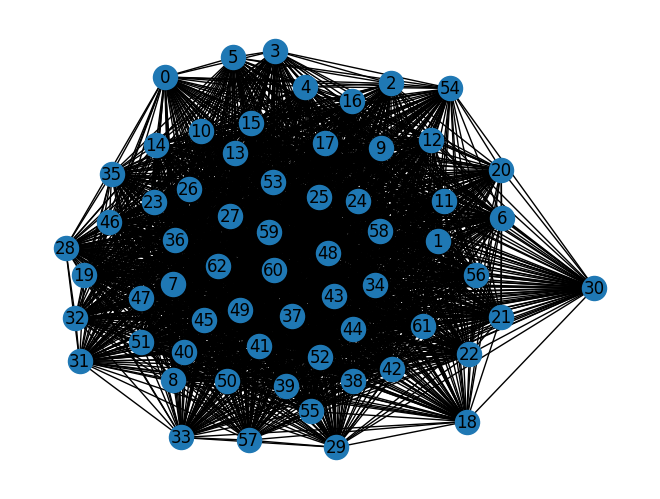

In [ ]:
nx.draw_spring(G_pos, with_labels=True)